# **1. Setup**

### **Import Library**

In [1]:
!pip install -q segmentation_models_pytorch pytorch-optimizer xgboost geopandas contextily shapely adjustText

In [2]:
import os
import json, time, math, random
from pathlib import Path
from functools import partial
import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.colors import LogNorm
from adjustText import adjust_text
from matplotlib.patches import Patch, Polygon as MplPolygon
from matplotlib.ticker import FuncFormatter, MaxNLocator
from shapely.geometry import Polygon as ShapelyPolygon
from shapely.prepared import prep
import contextily as cx
from pytorch_optimizer import SOAP
from scipy import ndimage as ndi
from scipy.stats import friedmanchisquare, wilcoxon
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import average_precision_score, precision_recall_curve, brier_score_loss
import segmentation_models_pytorch as smp
import xgboost as xgb
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

### **Global Configuration**

In [3]:
SEED = 42
def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
seed_all(SEED)

In [ ]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SMOKE = False
RETRAIN = True
H = 3
PATCH_SIZE = 64
RESOLUTION_M = 375.0
BUFFER_RADII = (4, 6, 8)
EPOCHS = 10 if SMOKE else 100
BATCH_SIZE = 32
LR = 1e-4
POS_W_MAX = 5.0

In [5]:
ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
RESULT_DIR = ROOT / 'results'
CKPT_DIR = ROOT / 'checkpoints'
for d in [RESULT_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)
test_loaded = False

In [ ]:
sns.set_theme(
    style="ticks",
    context="paper",
     font="DejaVu Sans",
    font_scale=1.1,
    rc={
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "axes.linewidth": 0.8,
        "axes.labelsize": 10,
        "axes.titlesize": 11,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "lines.linewidth": 1.8,
        "lines.markersize": 5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)
SCIENTIFIC_PALETTE = [
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#009E73",  # Green
    "#D55E00",  # Red
    "#CC79A7",  # Purple
    "#8C564B",  # Brown
]
SPLIT_PALETTE = {'Data Latih': SCIENTIFIC_PALETTE[0], 'Data Validasi': SCIENTIFIC_PALETTE[1]}
IGBP_LABELS_ID = {
    2: 'Hutan Berdaun Lebar Hijau', 4: 'Hutan Berdaun Lebar Gugur', 5: 'Hutan Campuran',
    6: 'Semak Belukar Tertutup', 7: 'Semak Belukar Terbuka', 8: 'Sabana Berkayu',
    9: 'Sabana', 10: 'Padang Rumput', 11: 'Lahan Basah / Rawa Gambut',
    12: 'Lahan Pertanian', 13: 'Permukiman & Terbangun', 14: 'Mosaik Pertanian–Vegetasi',
    16: 'Lahan Terbuka', 17: 'Badan Air',
}
sns.set_palette(SCIENTIFIC_PALETTE)

# **2. Data Preparation**

#### **Download Dataset from Kaggle**

In [7]:
try:
    import kagglehub
    kaggle_data_path = kagglehub.dataset_download('sanantaaulgard/borneo-island-wildfire-spread-dataset')
    DATA_DIR = Path(kaggle_data_path)
except Exception:
    DATA_DIR = ROOT / 'data'

Using Colab cache for faster access to the 'borneo-island-wildfire-spread-dataset' dataset.


In [8]:
def load_npz(split, max_n=None):
    path = DATA_DIR / f'{split}.npz'
    raw = np.load(path, mmap_mode='r')
    keys = ['x', 'y', 'y_new', 'valid', 'state_t', 'ca_phys', 'forcing_g', 'scalars', 'bbox', 'center_coord', 'date', 'timestamps', 'event_id', 'province']
    d = {}
    for k in keys:
        if k in raw:
            arr = raw[k] if max_n is None else raw[k][:max_n]
            d[k] = np.array(arr, dtype=np.float32 if arr.dtype == np.float16 else arr.dtype)
    if 'burned_t' not in d and 'y' in d and 'y_new' in d:
        d['burned_t'] = d['y'][:, 0] & ~d['y_new'][:, 0]
    return d

### **Load Train & Val Dataset**

In [9]:
max_tr = 80 if SMOKE else None
max_va = 32 if SMOKE else None
train_d = load_npz('train', max_n=max_tr)
val_d = load_npz('val', max_n=max_va)

In [10]:
dim_summary = pd.DataFrame([
    {'Split': 'Train', 'Samples': len(train_d['x']), 'x_shape': str(train_d['x'].shape), 'y_new_shape': str(train_d['y_new'].shape)},
    {'Split': 'Val', 'Samples': len(val_d['x']), 'x_shape': str(val_d['x'].shape), 'y_new_shape': str(val_d['y_new'].shape)}
])
dim_summary

,Split,Samples,x_shape,y_new_shape
0,Train,3699,"(3699, 32, 64, 64)","(3699, 3, 64, 64)"
1,Val,790,"(790, 32, 64, 64)","(790, 3, 64, 64)"


In [11]:
b0 = train_d['y'][:, 0] & ~train_d['y_new'][:, 0]
assert (b0 == train_d['burned_t']).all()
assert not (train_d['y_new'] & train_d['burned_t'][:, None]).any()
y_new_prev = train_d['y_new'].sum() / (train_d['y_new'].size) * 100

print(f'proporsi y_new: {y_new_prev:.4f}%')

proporsi y_new: 0.3131%


In [12]:
lon_span = train_d['bbox'][:, 2] - train_d['bbox'][:, 0]
lat_span = train_d['bbox'][:, 3] - train_d['bbox'][:, 1]
assert (lon_span > 0).all() and (lat_span > 0).all()
assert len(train_d['date']) == len(train_d['x'])

In [13]:
th_w = train_d['ca_phys'][:, 1]
th_s = train_d['ca_phys'][:, 3]
assert (th_w >= 0).all() and (th_w <= 2 * math.pi + 1e-4).all()
assert (th_s >= 0).all() and (th_s <= 2 * math.pi + 1e-4).all()

# **3. Exploratory Data Analysis (EDA)**

### **Plot Configuration**

In [14]:
def unnormalize_channel(arr, ch_name, ch_stats):
    st = ch_stats[ch_name]
    if st.get('is_categorical', False) or st.get('is_binary_or_trig', False):
        return arr.astype(np.float32)
    raw = arr.astype(np.float32) * float(st['std']) + float(st['mean'])
    return np.expm1(np.clip(raw, -20.0, 20.0)) if st.get('apply_log1p', False) else raw

def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'BT' if x >= 0 else 'BB'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'LU' if y >= 0 else 'LS'}"))
    ax.grid(color='grey', linewidth=0.4, alpha=0.5, linestyle='--')

def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate('U', xy=(x, y), xytext=(x, y - 0.11), xycoords='axes fraction',
                ha='center', va='center', fontsize=9, fontweight='bold',
                arrowprops=dict(facecolor='black', edgecolor='white', width=3, headwidth=9))

def add_scalebar(ax, x=0.04, y=0.05):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2.0))
    width_km = max((xmax - xmin) * km_per_deg, 1e-3)
    length_km = next((n for n in (500, 200, 100, 50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4.0), 0.5)
    length_deg = length_km / km_per_deg
    x0, y0, height = xmin + x * (xmax - xmin), ymin + y * (ymax - ymin), (ymax - ymin) * 0.014
    for i in range(2):
        ax.add_patch(plt.Rectangle((x0 + i * length_deg / 2.0, y0), length_deg / 2.0, height,
                                   facecolor='black' if i == 0 else 'white', edgecolor='black', linewidth=0.7, zorder=10))
    for frac in (0.0, 0.5, 1.0):
        ax.text(x0 + frac * length_deg, y0 + height * 1.6, f'{length_km * frac:g}', ha='center', va='bottom',
                fontsize=7, bbox=dict(facecolor='white', edgecolor='none', alpha=0.75, pad=0.8), zorder=10)
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, 'km', va='bottom', fontsize=7, zorder=10)

def add_esri_basemap(ax, extent, alpha=1.0, attribution_size=6):
    if cx is None:
        return
    try:
        zoom = cx.tile._calculate_zoom(extent[0], extent[2], extent[1], extent[3]) + 1
        cx.add_basemap(ax, crs='EPSG:4326', source=cx.providers.Esri.WorldShadedRelief,
                       zoom=zoom, alpha=alpha, attribution_size=attribution_size)
    except Exception:
        pass

def setup_kalimantan_map(ax, prov_gdf, lw=0.9, attribution_size=6, north_xy=(0.94, 0.92), scale_xy=(0.04, 0.05)):
    xmin, ymin, xmax, ymax = prov_gdf.total_bounds
    pad = 0.45
    extent = [xmin - pad, xmax + pad, ymin - pad, ymax + pad]
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect('equal')
    add_esri_basemap(ax, extent, alpha=0.65, attribution_size=attribution_size)
    prov_gdf.plot(ax=ax, facecolor='none', edgecolor='#1a202c', linewidth=lw, zorder=4)
    add_lonlat(ax)
    add_north_arrow(ax, x=north_xy[0], y=north_xy[1])
    add_scalebar(ax, x=scale_xy[0], y=scale_xy[1])
    ax.set_xlabel('Bujur')
    ax.set_ylabel('Lintang')

def save_and_show(fig, filename):
    plt.show()
    plt.close(fig)

def smooth_mask(mask_2d, scale=4, sigma=1.3):
    return ndi.gaussian_filter(ndi.zoom(mask_2d.astype(np.float32), scale, order=1), sigma=sigma) >= 0.45

In [15]:
def load_kalimantan_provinces(df_fallback):
    candidates = [
        ROOT / 'output/gadm/kalimantan_provinces.parquet',
        DATA_DIR / 'kalimantan_provinces.parquet',
        RESULT_DIR / 'kalimantan_provinces.parquet',
    ]
    for p in candidates:
        if p.exists():
            return gpd.read_parquet(p).to_crs('EPSG:4326')
    try:
        gdf = gpd.read_file('https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip')
        kal = gdf[gdf['NAME_1'].str.contains('Kalimantan', na=False)].copy()
        kal['province_name'] = kal['NAME_1'].str.replace('Kalimantan', 'Kalimantan ', regex=False).str.strip()
        kal = kal[['province_name', 'geometry']].to_crs('EPSG:4326')
        kal.to_parquet(RESULT_DIR / 'kalimantan_provinces.parquet')
        return kal
    except Exception:
        pts = gpd.GeoDataFrame(
            {'province_name': df_fallback['province']},
            geometry=gpd.points_from_xy(df_fallback['lon'], df_fallback['lat']),
            crs='EPSG:4326',
        )
        return pts.dissolve(by='province_name').convex_hull.reset_index(name='geometry')

def _masked_mean(arr, mask):
    cnt = mask.sum(axis=(1, 2))
    return np.where(cnt > 0, (arr * mask).sum(axis=(1, 2)) / np.maximum(cnt, 1), arr.mean(axis=(1, 2)))

def build_eda_data(train_d, val_d):
    meta = json.loads((DATA_DIR / 'metadata.json').read_text(encoding='utf-8'))
    ch_idx = {name: i for i, name in enumerate(meta['core_32_channels'])}
    ch_stats = meta['normalization_stats']['channels']
    raw_arrays = {'Data Latih': train_d, 'Data Validasi': val_d}
    frames = []
    for sp, d in raw_arrays.items():
        x, y, yn = d['x'], d['y'], d['y_new']
        v = d['valid'] > 0
        v_h1, v_h2, v_h3 = v[:, 0], v[:, 1], v[:, 2]
        dates = pd.to_datetime(d['date'].astype(str))
        coords = d['center_coord'] if 'center_coord' in d else np.stack([(d['bbox'][:, 0] + d['bbox'][:, 2]) / 2, (d['bbox'][:, 1] + d['bbox'][:, 3]) / 2], axis=1)
        peat = unnormalize_channel(x[:, ch_idx['peat']], 'peat', ch_stats)
        dist_rd = unnormalize_channel(x[:, ch_idx['dist_road']], 'dist_road', ch_stats)
        floss = unnormalize_channel(x[:, ch_idx['forest_loss_cum']], 'forest_loss_cum', ch_stats)
        lc_arr = np.rint(x[:, ch_idx['landcover_idx']]).astype(np.int32)
        dom_lc = np.array([
            int(np.bincount((lc_arr[i][v_h3[i]] if v_h3[i].any() else lc_arr[i].ravel()).clip(min=0)).argmax())
            for i in range(len(y))
        ])
        yn_px = [(yn[:, h] & v[:, h]).sum(axis=(1, 2)) for h in range(H)]
        peat_frac = np.where(v_h3.any(axis=(1, 2)), _masked_mean(peat > 0.5, v_h3), 0.0)
        floss_frac = np.where(v_h3.any(axis=(1, 2)), _masked_mean(floss > 0.5, v_h3), 0.0)
        frames.append(pd.DataFrame({
            'split': sp,
            'idx': np.arange(len(y)),
            'event_id': d['event_id'].astype(np.int32),
            'date': dates,
            'year': dates.year,
            'month': dates.month,
            'province': d['province'].astype(str),
            'lon': coords[:, 0].astype(np.float32),
            'lat': coords[:, 1].astype(np.float32),
            'oni': d['scalars'][:, 0].astype(np.float32),
            'dmi': d['scalars'][:, 1].astype(np.float32),
            'init_fire_px': ((d['state_t'][:, 1] > 0.5) & v_h1).sum(axis=(1, 2)),
            'y_h1_px': (y[:, 0] & v_h1).sum(axis=(1, 2)),
            'y_h2_px': (y[:, 1] & v_h2).sum(axis=(1, 2)),
            'y_h3_px': (y[:, 2] & v_h3).sum(axis=(1, 2)),
            'yn_h1_px': yn_px[0],
            'yn_h2_px': yn_px[1],
            'yn_h3_px': yn_px[2],
            'yn_total_px': yn_px[0] + yn_px[1] + yn_px[2],
            'valid_h3_frac': v_h3.mean(axis=(1, 2)),
            'peat_frac': peat_frac,
            'is_peat_dom': np.where(peat_frac >= 0.5, 'Lahan Gambut', 'Lahan Non-Gambut'),
            'dist_road_mean': _masked_mean(dist_rd, v_h3),
            'floss_frac': floss_frac,
            'dom_lc': dom_lc,
        }))
    return pd.concat(frames, ignore_index=True), raw_arrays

eda_df, eda_arrays = build_eda_data(train_d, val_d)
prov_gdf = load_kalimantan_provinces(eda_df)
print(f'Total patch EDA termuat: {len(eda_df)}')

Total patch EDA termuat: 4489


#### Spatial Distribution of Wildfire Spread Intensity Across Kalimantan

In [16]:
def plot_spatial_hexbin(df, prov_gdf):
    fig, ax = plt.subplots(figsize=(9.5, 8.2))
    setup_kalimantan_map(ax, prov_gdf, lw=1.15, attribution_size=7, north_xy=(0.94, 0.93), scale_xy=(0.04, 0.05))
    xmin, ymin, xmax, ymax = prov_gdf.total_bounds
    kal_union = prov_gdf.geometry.union_all()
    kal_prep = prep(kal_union)
    r, angles = 0.08, np.linspace(0, 2 * np.pi, 7)[:-1]
    dx, dy = 1.5 * r, np.sqrt(3.0) * r
    lons, lats, weights = df['lon'].to_numpy(), df['lat'].to_numpy(), df['yn_total_px'].to_numpy() + 1.0
    hex_polys, hex_vals = [], []
    for ci, cx_pt in enumerate(np.arange(xmin - r, xmax + r, dx)):
        y_off = (dy / 2.0) if (ci % 2 == 1) else 0.0
        for cy_pt in np.arange(ymin - r + y_off, ymax + r, dy):
            poly = ShapelyPolygon([(cx_pt + r * np.cos(a), cy_pt + r * np.sin(a)) for a in angles])
            if not kal_prep.intersects(poly):
                continue
            clipped = poly if kal_prep.contains(poly) else poly.intersection(kal_union)
            if clipped.is_empty:
                continue
            in_hex = ((lons - cx_pt) ** 2 + (lats - cy_pt) ** 2) <= r ** 2
            val = 1.0 + (float(weights[in_hex].sum()) if np.any(in_hex) else 0.0)
            geoms = [clipped] if clipped.geom_type == 'Polygon' else (list(clipped.geoms) if clipped.geom_type == 'MultiPolygon' else [])
            for g in geoms:
                hex_polys.append(MplPolygon(list(g.exterior.coords), closed=True))
                hex_vals.append(val)
    hex_vals_arr = np.array(hex_vals, dtype=np.float64)
    pc = PatchCollection(hex_polys, cmap='magma_r', norm=LogNorm(vmin=1.0, vmax=max(float(hex_vals_arr.max()), 10.0)),
                         edgecolor='none', linewidths=0, alpha=0.88, zorder=5)
    pc.set_array(hex_vals_arr)
    ax.add_collection(pc)
    fig.colorbar(pc, ax=ax, fraction=0.036, pad=0.02).set_label('Intensitas Kumulatif Area Terbakar Baru (log10)', fontsize=9)
    for _, row in prov_gdf.iterrows():
        pt = row.geometry.representative_point()
        ax.text(pt.x, pt.y, str(row['province_name']).replace('Kalimantan ', 'Kal. '),
                fontsize=8, fontweight='bold', ha='center', va='center', color='#111111',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#cbd5e0', alpha=0.85), zorder=7)
    ax.set_title('Distribusi Spasial Intensitas Penjalaran Kebakaran di Kalimantan', pad=10, fontweight='bold')

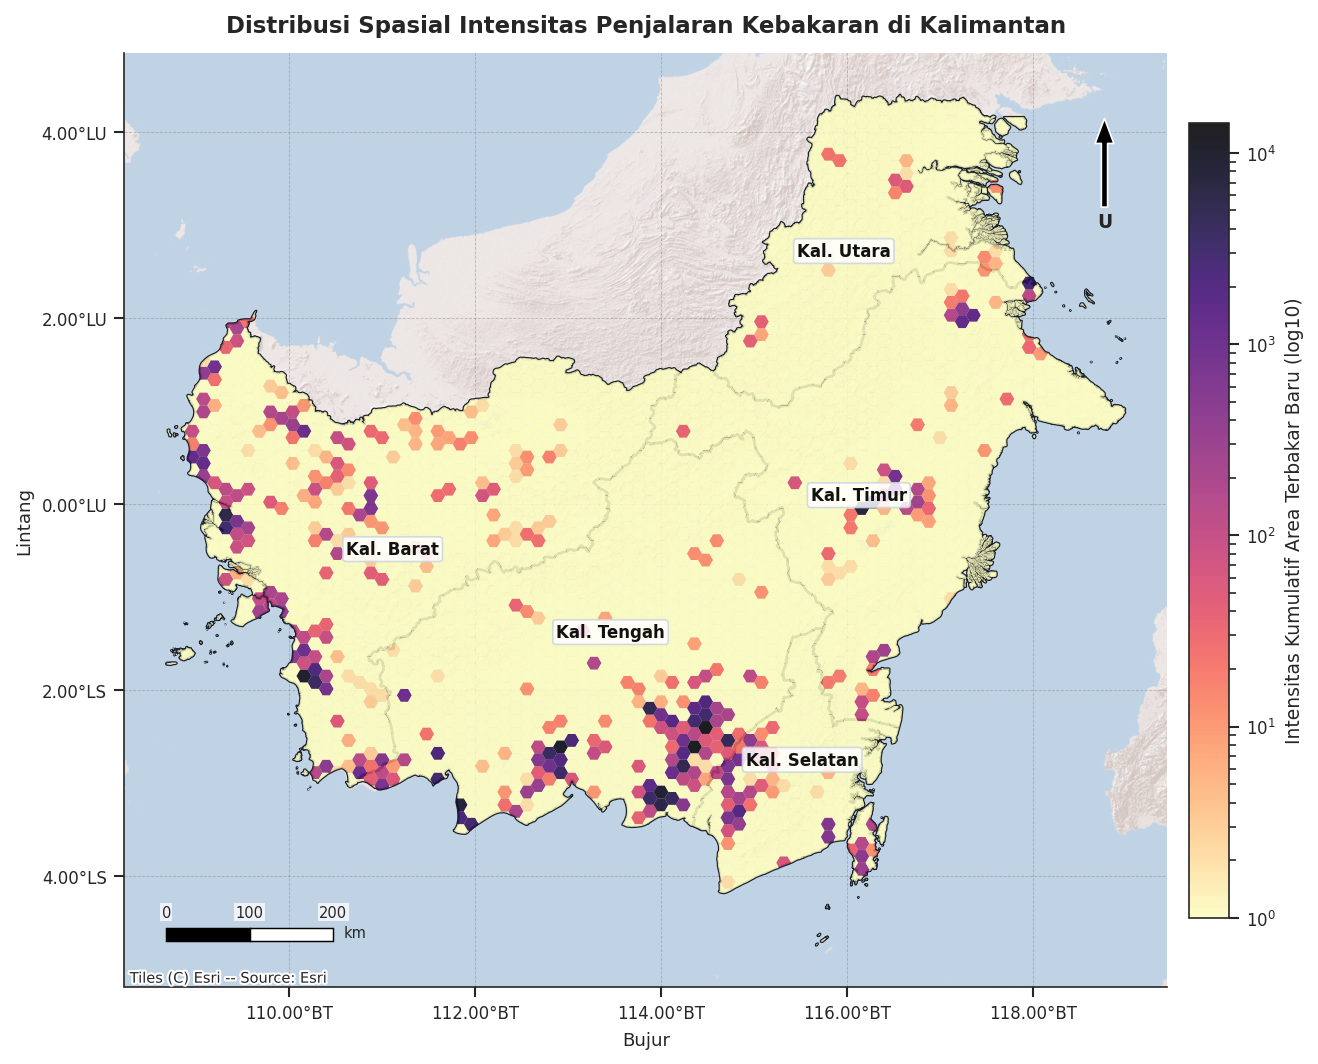

In [17]:
plot_spatial_hexbin(eda_df, prov_gdf)

#### Monthly Seasonality of Wildfire Occurrence and Spread Severity

In [ ]:
def plot_monthly_seasonality(df):
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
    rows = [
        {'Bulan': month_names[m - 1], 'Partisi': sp, 'Proporsi (%)': (sub['month'] == m).sum() / max(len(sub), 1) * 100.0}
        for sp in ['Data Latih', 'Data Validasi']
        for sub in [df[df['split'] == sp]]
        for m in range(1, 13)
    ]
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    sns.barplot(data=pd.DataFrame(rows), x='Bulan', y='Proporsi (%)', hue='Partisi', palette=SPLIT_PALETTE, ax=ax, edgecolor='white', linewidth=0.5)
    ax.axvspan(6.5, 9.5, color=SCIENTIFIC_PALETTE[2], alpha=0.15, zorder=0, label='Puncak Musim Kemarau (Agu–Okt)')
    ax2 = ax.twinx()
    ax2.spines['top'].set_visible(False)
    overall_m = df.groupby('month')['yn_total_px'].mean().reindex(range(1, 13), fill_value=0.0)
    ax2.plot(np.arange(12), overall_m.to_numpy(), color=SCIENTIFIC_PALETTE[3], marker='o', linewidth=2.0, label='Area Terbakar Baru')
    ax2.set_ylabel('Rata-rata Area Terbakar Baru', color=SCIENTIFIC_PALETTE[3])
    ax2.tick_params(axis='y', colors=SCIENTIFIC_PALETTE[3])
    ax2.set_ylim(0, max(overall_m.max() * 1.25, 1.0) * 1.05)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc='upper left', frameon=True, facecolor='white', edgecolor='#e2e8f0')
    ax.set_title('Tren Musiman Kejadian dan Tingkat Keparahan Kebakaran Bulanan', fontweight='bold')
    ax.set_xlabel('Bulan Kalender')
    ax.set_ylabel('Proporsi (%)')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.05)
    ax.grid(axis='y', linestyle='--', alpha=0.35)

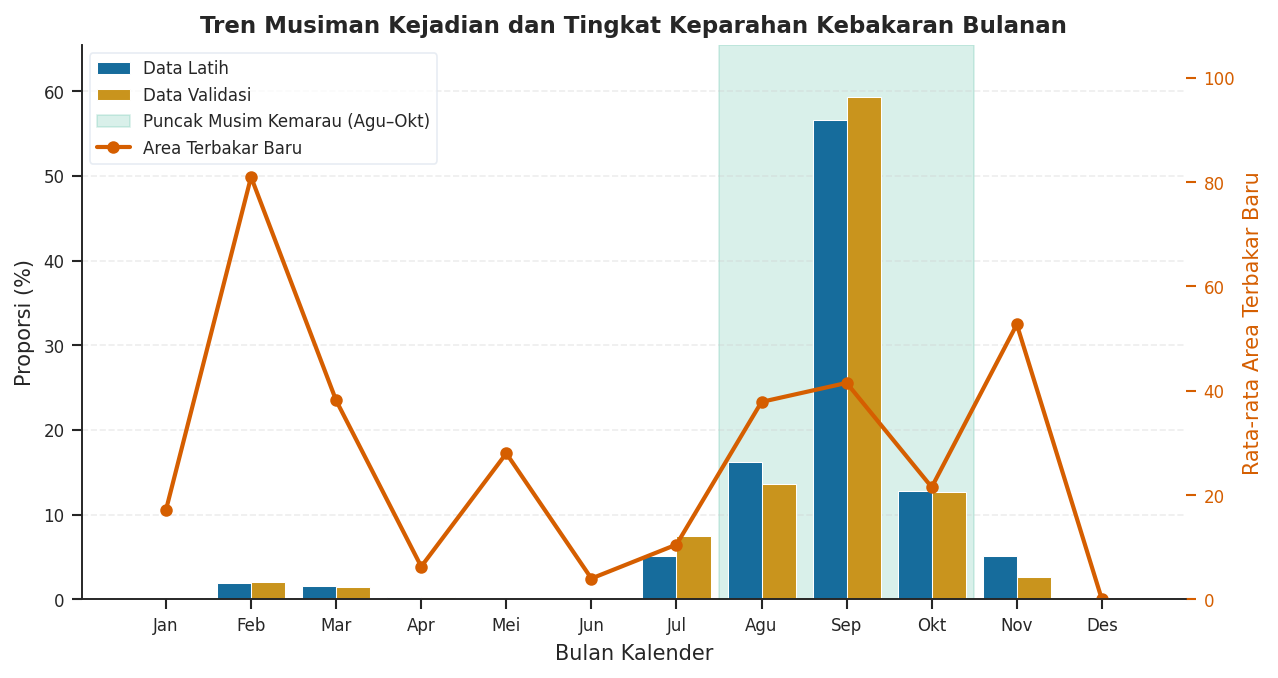

In [19]:
plot_monthly_seasonality(eda_df)

#### Extreme Class Imbalance Analysis Across Multi-Horizon Fire Targets

In [20]:
def plot_target_imbalance_2x1(raw_arrays):
    targets = [('y_new', 'Target Piksel Terbakar Baru (y_new)'), ('y', 'Target Area Terbakar Kumulatif (y)')]
    horizons = [('t+1 (24 jam)', 0), ('t+2 (48 jam)', 1), ('t+3 (72 jam)', 2)]
    records = []
    for t_key, t_label in targets:
        tot_pos, tot_neg = 0, 0
        for h_name, h_i in horizons:
            pos = sum(int(((d[t_key][:, h_i] > 0) & (d['valid'][:, h_i] > 0)).sum()) for d in raw_arrays.values())
            neg = sum(int((~(d[t_key][:, h_i] > 0) & (d['valid'][:, h_i] > 0)).sum()) for d in raw_arrays.values())
            tot = max(pos + neg, 1)
            tot_pos, tot_neg = tot_pos + pos, tot_neg + neg
            records.extend([
                {'Target': t_label, 'Horizon': h_name, 'Kelas': 'Tidak Terbakar (0)', 'Jumlah': neg, 'Persen': neg / tot * 100.0},
                {'Target': t_label, 'Horizon': h_name, 'Kelas': 'Terbakar (1)', 'Jumlah': pos, 'Persen': pos / tot * 100.0},
            ])
        gtot = max(tot_pos + tot_neg, 1)
        records.extend([
            {'Target': t_label, 'Horizon': 'Keseluruhan', 'Kelas': 'Tidak Terbakar (0)', 'Jumlah': tot_neg, 'Persen': tot_neg / gtot * 100.0},
            {'Target': t_label, 'Horizon': 'Keseluruhan', 'Kelas': 'Terbakar (1)', 'Jumlah': tot_pos, 'Persen': tot_pos / gtot * 100.0},
        ])
    imb_df = pd.DataFrame(records)
    fig, axes = plt.subplots(2, 1, figsize=(8.8, 7.6), sharex=True)
    cls_palette = {'Tidak Terbakar (0)': SCIENTIFIC_PALETTE[1], 'Terbakar (1)': SCIENTIFIC_PALETTE[3]}
    h_order = ['t+1 (24 jam)', 't+2 (48 jam)', 't+3 (72 jam)', 'Keseluruhan']
    c_order = ['Tidak Terbakar (0)', 'Terbakar (1)']
    for ax, (_, t_label) in zip(axes, targets):
        sub = imb_df[imb_df['Target'] == t_label]
        sns.barplot(data=sub, x='Horizon', y='Jumlah', hue='Kelas', palette=cls_palette, ax=ax, edgecolor='white', linewidth=0.6)
        ax.set_yscale('log')
        ax.set_ylim(1e3, sub['Jumlah'].max() * 14.0)
        ax.set_ylabel('Jumlah Piksel Valid (skala log)')
        ax.grid(axis='y', linestyle='--', alpha=0.35)
        for c_i, cls_name in enumerate(c_order):
            c_sub = sub[sub['Kelas'] == cls_name].set_index('Horizon').loc[h_order]
            for bar, (_, row) in zip(ax.containers[c_i], c_sub.iterrows()):
                pct = row['Persen']
                ax.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height() * 1.18,
                        f'{pct:.2f}%' if pct >= 1.0 else f'{pct:.3f}%', ha='center', va='bottom',
                        fontsize=8, color='#2d3748')
        ov_pos = sub[(sub['Horizon'] == 'Keseluruhan') & (sub['Kelas'] == 'Terbakar (1)')]['Persen'].iloc[0]
        ax.set_title(f"{t_label} — Rasio Ketidakseimbangan (≈{(100.0 - ov_pos) / max(ov_pos, 1e-9):.0f}:1)", fontweight='bold')
        ax.legend(loc='upper center', ncol=2, frameon=True, facecolor='white', edgecolor='#e2e8f0')
    axes[1].set_xlabel('Horizon Prediksi')
    # fig.suptitle('Analisis Ketidakseimbangan Kelas Ekstrem pada Target Piksel Kebakaran', fontsize=12, fontweight='bold', y=1.01)

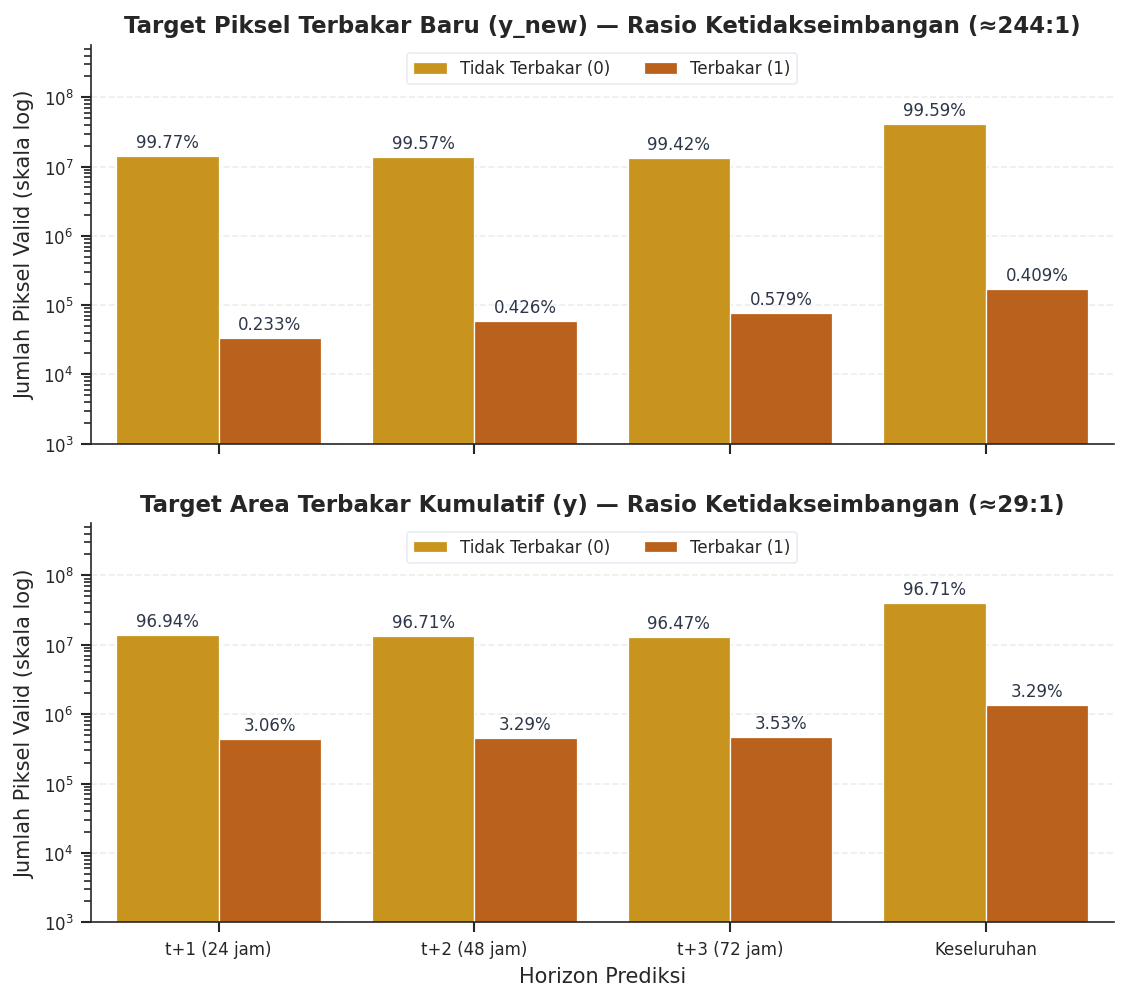

In [21]:
plot_target_imbalance_2x1(eda_arrays)

#### Multi-Horizon Wildfire Spread Progression and Target Masking

In [22]:
def plot_progression_samples(df, raw_arrays):
    chosen = []
    for sp in ['Data Latih', 'Data Validasi']:
        max_init, min_val = (48, 0.85) if sp == 'Data Latih' else (90, 0.70)
        sub = df[(df['split'] == sp) & (df['init_fire_px'] >= 5) & (df['init_fire_px'] <= max_init)
                 & (df['y_h3_px'] > df['y_h2_px']) & (df['y_h2_px'] > df['y_h1_px']) & (df['y_h1_px'] > df['init_fire_px'])
                 & (df['yn_h3_px'] >= 60) & (df['valid_h3_frac'] >= min_val)].copy()
        if sub.empty:
            sub = df[df['split'] == sp].copy()
        if sp == 'Data Validasi' and chosen:
            sub_diff = sub[sub['province'] != chosen[0]['province']]
            if len(sub_diff) > 0:
                sub = sub_diff
        chosen.append(sub.sort_values(['yn_h3_px', 'valid_h3_frac'], ascending=[False, False]).iloc[0].to_dict())
    def _smooth_mask(mask_2d, sigma=1.3):
        return ndi.gaussian_filter(ndi.zoom(mask_2d.astype(np.float32), 4, order=1), sigma=sigma) >= 0.45
    fig, axes = plt.subplots(2, 4, figsize=(16.5, 8.8))
    stage_titles = ['Hari t (Api Awal)', 'Hari t+1 (24 jam)', 'Hari t+2 (48 jam)', 'Hari t+3 (72 jam)']
    for row_i, s_meta in enumerate(chosen):
        arr = raw_arrays[s_meta['split']]
        idx = int(s_meta['idx'])
        bb = arr['bbox'][idx]
        extent = [float(bb[0]), float(bb[2]), float(bb[1]), float(bb[3])]
        st, y, yn, val_m = arr['state_t'][idx], arr['y'][idx], arr['y_new'][idx], arr['valid'][idx] > 0
        for col_i in range(4):
            ax = axes[row_i, col_i]
            ax.set_xlim(extent[0], extent[1])
            ax.set_ylim(extent[2], extent[3])
            ax.set_aspect('equal')
            add_esri_basemap(ax, extent, attribution_size=6 if (row_i == 1 and col_i == 0) else 0)
            rgba = np.zeros((256, 256, 4), dtype=np.float32)
            v_mask = val_m[0 if col_i == 0 else col_i - 1]
            rgba[_smooth_mask(~v_mask, sigma=1.1)] = [0.39, 0.45, 0.55, 0.40]
            if col_i == 0:
                active_t = (st[1] > 0.5) & v_mask
                rgba[_smooth_mask((st[2] > 0.5) & v_mask)] = [0.45, 0.22, 0.16, 0.65]
                rgba[_smooth_mask(active_t, sigma=1.2)] = [0.79, 0.64, 0.15, 0.95]
                px_txt = f'Api Aktif = {int(active_t.sum())} px'
            else:
                h_i = col_i - 1
                cum_y, new_y = (y[h_i] > 0) & v_mask, (yn[h_i] > 0) & v_mask
                rgba[_smooth_mask(cum_y & ~new_y)] = [0.55, 0.15, 0.15, 0.70]
                rgba[_smooth_mask(new_y)] = [0.88, 0.48, 0.25, 0.92]
                px_txt = f'Kum = {int(cum_y.sum())*375/10000:.2f} ha | Baru = {int(new_y.sum())*375/10000:.2f} ha'
            ax.imshow(rgba, extent=extent, origin='upper', interpolation='bilinear', zorder=5)
            add_lonlat(ax)
            ax.xaxis.set_major_locator(MaxNLocator(3))
            ax.yaxis.set_major_locator(MaxNLocator(4))
            if col_i == 0:
                add_north_arrow(ax, x=0.90, y=0.89)
                add_scalebar(ax, x=0.05, y=0.06)
                ax.set_ylabel(f"Sampel {row_i + 1}: {s_meta['province']}\n({s_meta['date'].strftime('%d %b %Y')})", fontsize=9.5, fontweight='bold')
            else:
                ax.tick_params(labelleft=False)
            if row_i == 0:
                ax.tick_params(labelbottom=False)
            ax.set_title(f'{stage_titles[col_i]}\n{px_txt}', fontsize=8, fontweight='bold')
    legend_handles = [
        Patch(facecolor=(0.79, 0.64, 0.15, 0.95), edgecolor='black', label='Api Aktif Awal (t)'),
        Patch(facecolor=(0.55, 0.15, 0.15, 0.72), edgecolor='black', label='Area Terbakar Kumulatif (y)'),
        Patch(facecolor=(0.88, 0.48, 0.25, 0.92), edgecolor='black', label='Perluasan Terbakar Baru (y_new)'),
        Patch(facecolor=(0.39, 0.45, 0.55, 0.45), edgecolor='black', label='Area Termasking (Awan/Air)'),
    ]
    fig.legend(handles=legend_handles, loc='lower center', ncol=4, frameon=True, facecolor='white', bbox_to_anchor=(0.5, -0.02))
    fig.suptitle('Visualisasi Perkembangan Perluasan Area Kebakaran dalam 72 Jam', fontsize=12.5, fontweight='bold', y=1.01)
    plt.tight_layout(rect=[0, 0.03, 1, 0.98], h_pad=3)

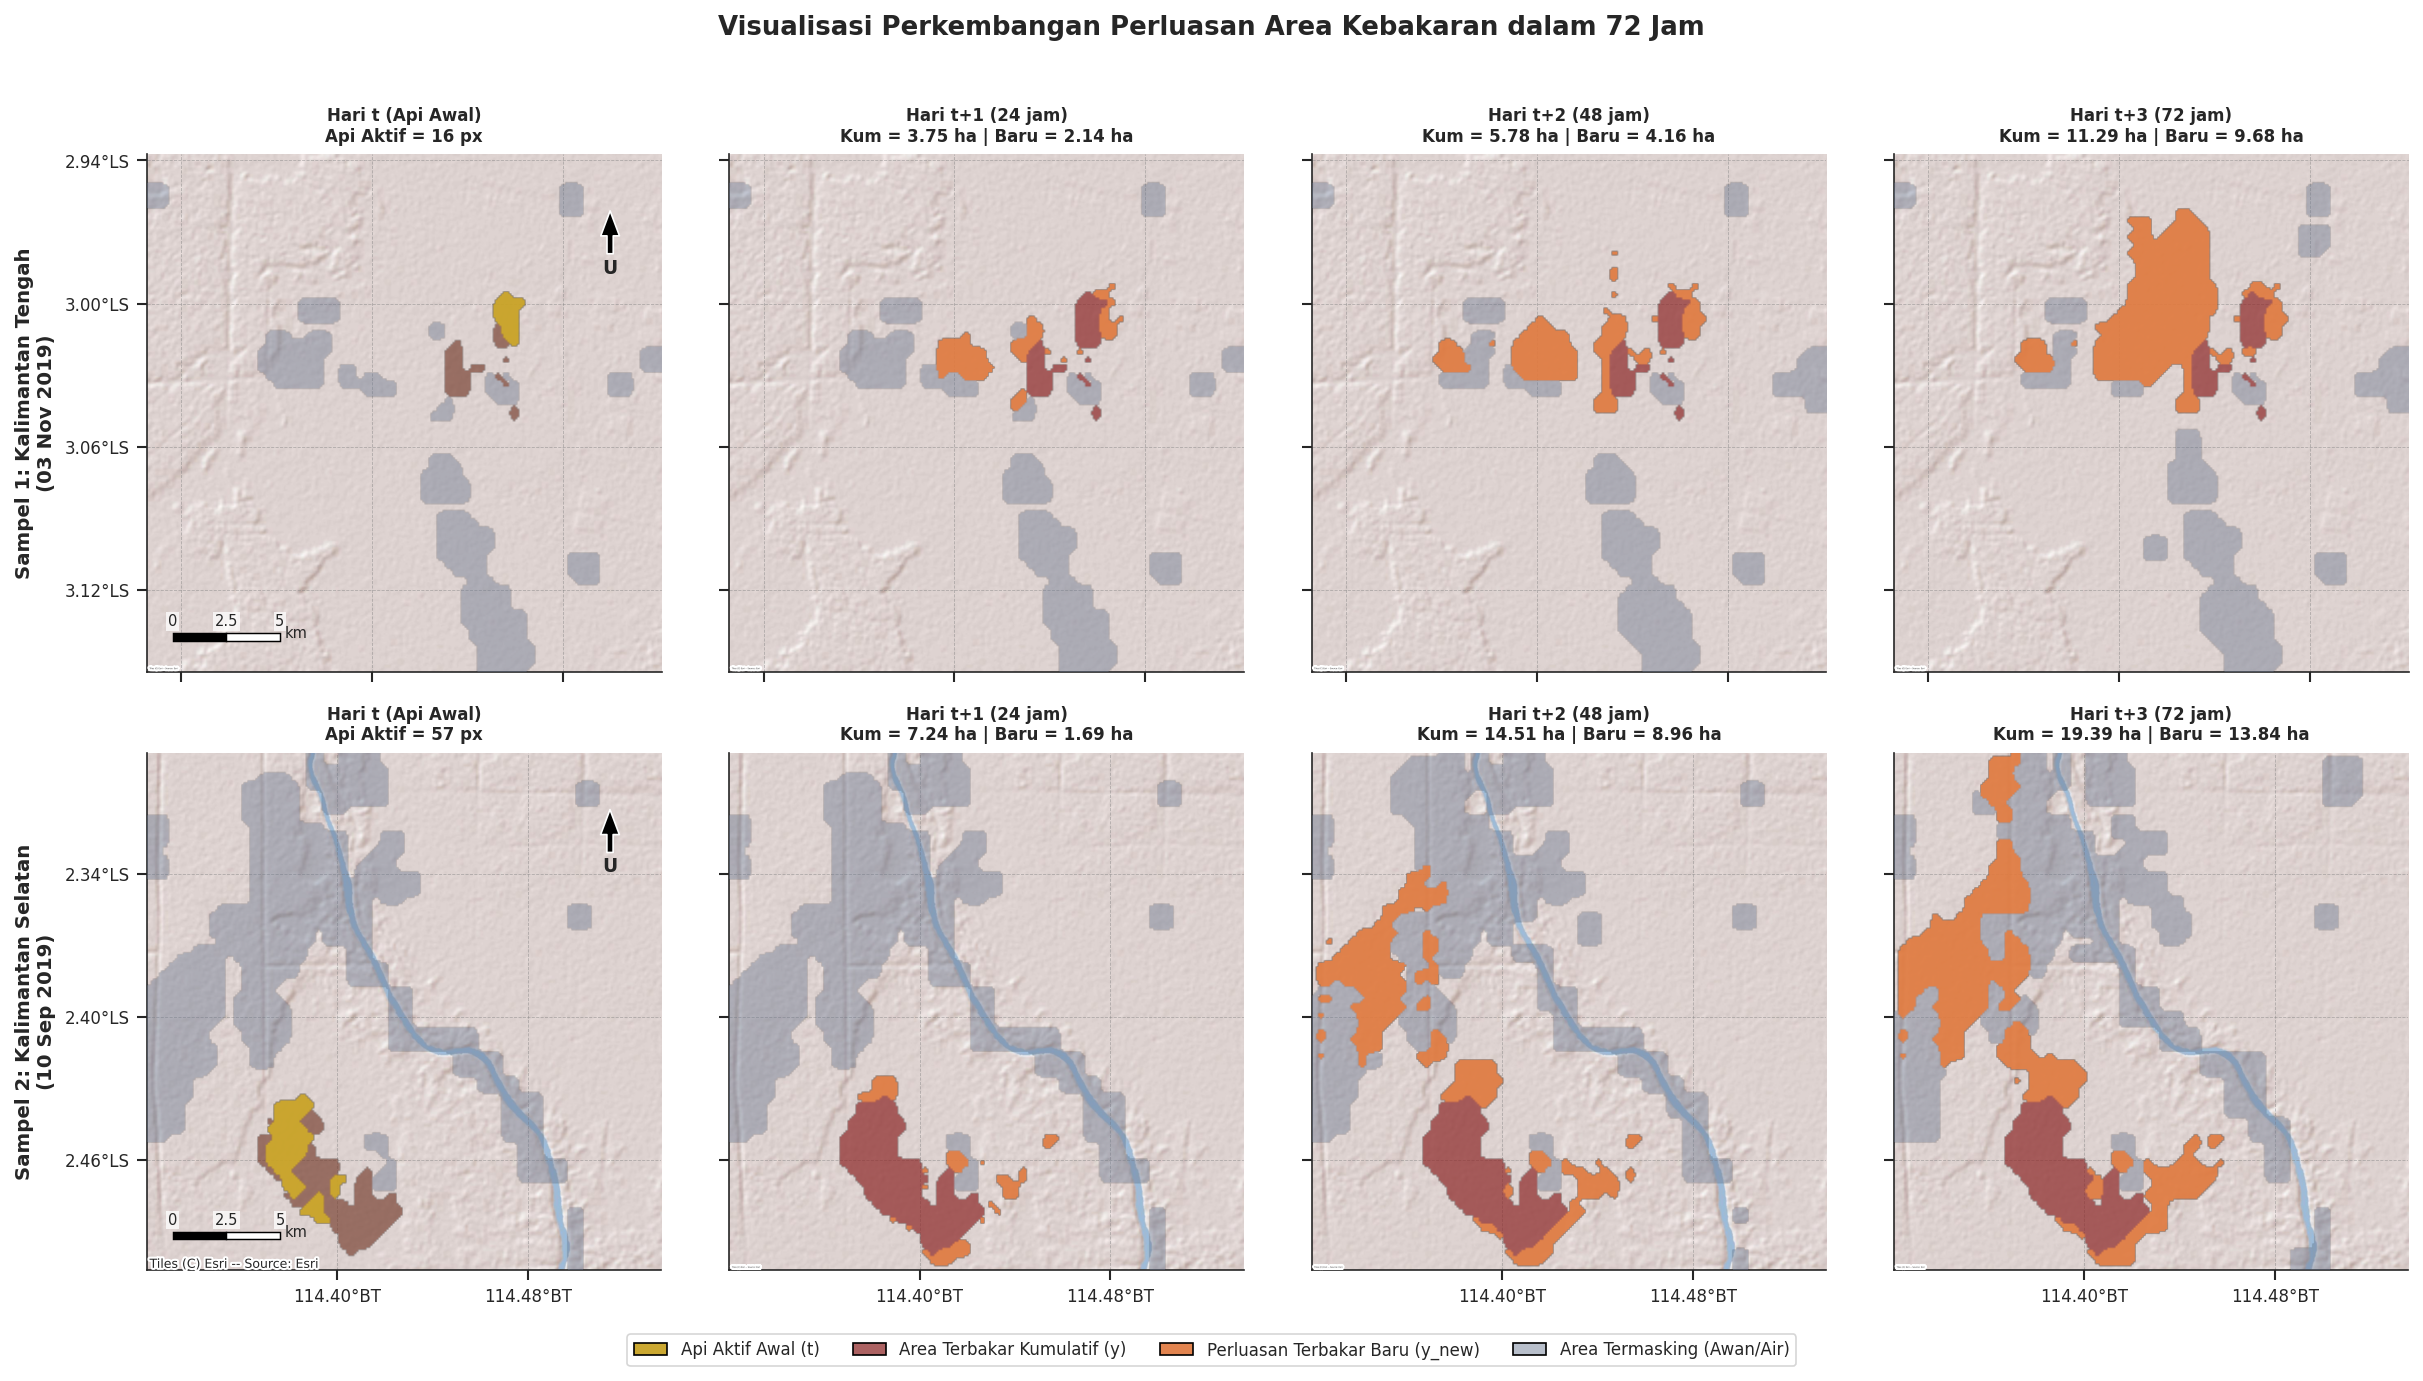

In [23]:
plot_progression_samples(eda_df, eda_arrays)

#### Dominant Land Cover Distribution and Anthropogenic Spread Drivers

In [24]:
def plot_landcover_map(df, prov_gdf):
    df = df.copy()
    top_lcs = df['dom_lc'].value_counts().head(6).index.tolist()
    df['Tutupan Lahan'] = df['dom_lc'].apply(
        lambda c: IGBP_LABELS_ID.get(c, f'Kelas {c}') if c in top_lcs else 'Lainnya'
    )
    cats = [IGBP_LABELS_ID.get(c, f'Kelas {c}') for c in top_lcs]
    if 'Lainnya' in df['Tutupan Lahan'].values:
        cats.append('Lainnya')

    markers_list = ['o', 's', '^', 'D', 'v', 'P', 'X']
    fig, ax = plt.subplots(figsize=(7.5, 6.0))
    setup_kalimantan_map(ax, prov_gdf, lw=0.9, attribution_size=6, north_xy=(0.93, 0.92), scale_xy=(0.04, 0.05))
    for i, cat in enumerate(cats):
        sub_c = df[df['Tutupan Lahan'] == cat]
        ax.scatter(
            sub_c['lon'], sub_c['lat'],
            marker=markers_list[i % len(markers_list)],
            color=SCIENTIFIC_PALETTE[i % len(SCIENTIFIC_PALETTE)],
            s=22, alpha=0.78, edgecolors='white',
            linewidths=0.3, label=cat, zorder=5
        )
    ax.set_title('Sebaran Tutupan Lahan Dominan pada Titik Kebakaran', fontweight='bold')
    leg = ax.legend(loc='lower right', fontsize=5, frameon=True, facecolor='white', markerscale=1.1, 
            title='Tutupan Lahan', title_fontsize=6.5)
    for text in leg.get_texts():
        text.set_fontweight('bold')
        leg.get_title().set_fontweight('bold')
    plt.tight_layout()
    plt.show()

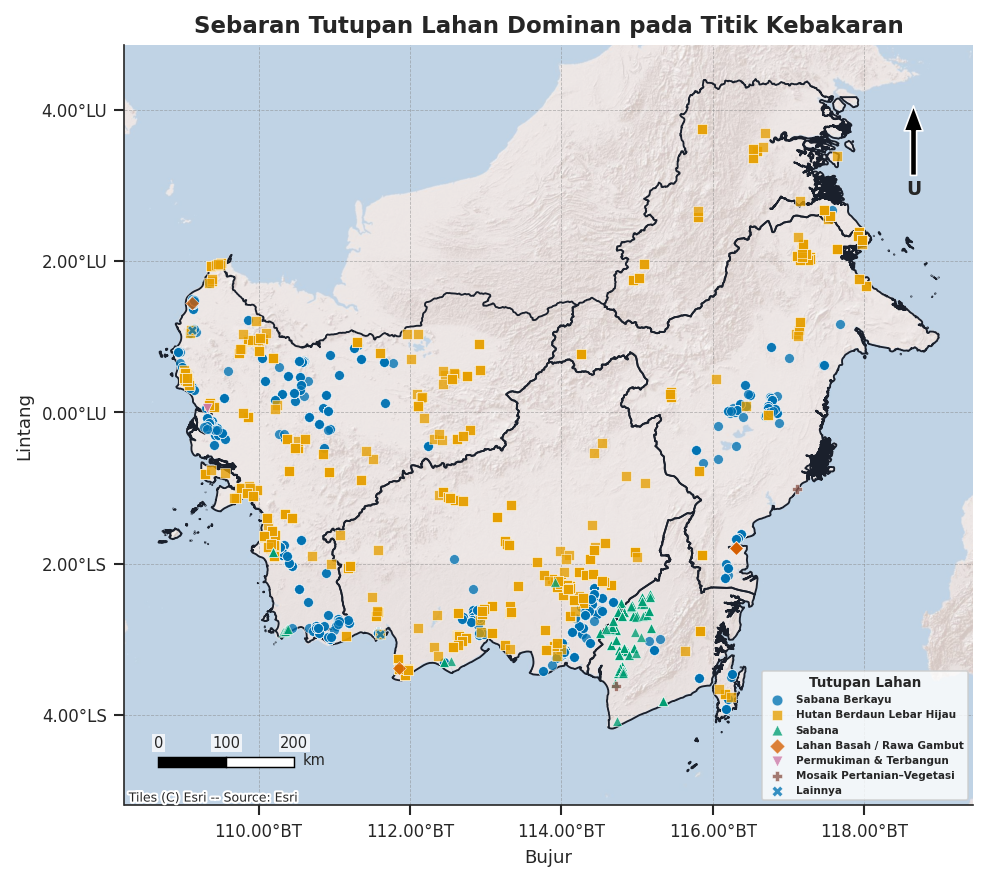

In [25]:
plot_landcover_map(eda_df, prov_gdf)

In [26]:
palette={'Terdeforestasi': SCIENTIFIC_PALETTE[1], 'Kanopi Utuh': SCIENTIFIC_PALETTE[2]}

In [27]:
def plot_road_deforestation_analysis(df):
    df = df.copy()
    df['dist_road_km'] = df['dist_road_mean'] / 1000.0
    df['area_ha'] = df['yn_total_px'] * 375 / 10000
    df['Riwayat Lahan'] = np.where(df['floss_frac'] >= 0.5, "Terdeforestasi", 'Kanopi Utuh')
    df['Jarak ke Jalan'] = pd.cut(df['dist_road_km'], bins=[0, 0.5, 1.0, 2.0, 4.0, 8.0, 60.0], labels=['<0,5', '0,5–1', '1–2', '2–4', '4–8', '>8 km'])
    fig, ax = plt.subplots(figsize=(7.5, 5.0))
    sns.barplot(data=df, x='Jarak ke Jalan', y='area_ha', hue='Riwayat Lahan',
        palette={'Terdeforestasi': SCIENTIFIC_PALETTE[3], 'Kanopi Utuh': SCIENTIFIC_PALETTE[1]},
        errorbar=('ci', 95), ax=ax, edgecolor='white')
    ax.set_xlabel('Rata-rata Jarak Patch ke Jalan Terdekat (km)')
    ax.set_ylabel('Rata-rata Area Terbakar Baru (ha)')
    ax.set_title('Faktor Antropogenik terhadap Persebaran Kebakaran', fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.legend(title='Riwayat Deforestasi', frameon=True, facecolor='white', fontsize=8, title_fontsize=9, edgecolor='#e2e8f0')
    plt.tight_layout()
    plt.show()

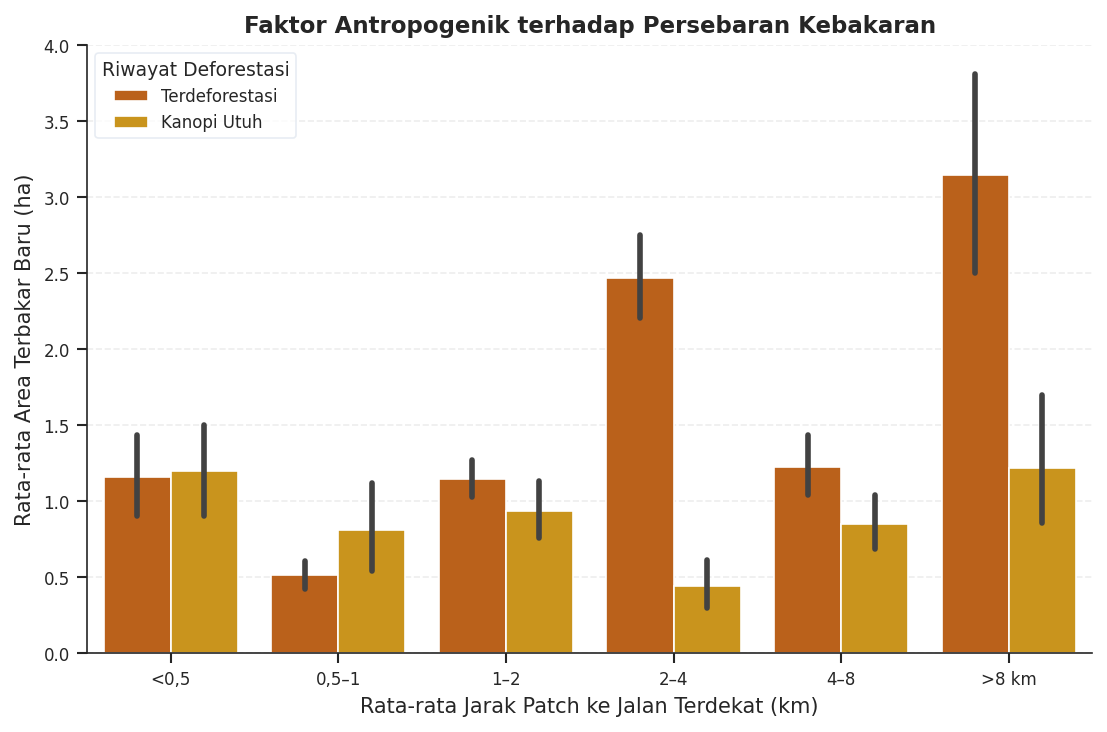

In [28]:
plot_road_deforestation_analysis(eda_df)

#### Polar Distribution of Wind Advection Direction at Active Fire Pixels

In [29]:
def plot_wind_polar(raw_arrays):
    thetas, spread_w = [], []
    for d in raw_arrays.values():
        v = d['valid'][:, 0] > 0
        m = (d['state_t'][:, 1] > 0.5) & v
        thetas.append(d['ca_phys'][:, 1][m])
        patch_yn = ((d['y_new'][:, 0] > 0) & v).sum(axis=(1, 2))
        spread_w.append(np.broadcast_to(patch_yn[:, None, None], m.shape)[m])
    th_all = np.concatenate(thetas) % (2 * np.pi)
    wt_all = np.concatenate(spread_w) + 1.0
    fig = plt.figure(figsize=(6.4, 6.0))
    ax = fig.add_subplot(1, 1, 1, projection='polar')
    n_bins = 24
    edges = np.linspace(0, 2 * np.pi, n_bins + 1)
    hist_cnt, _ = np.histogram(th_all, bins=edges, density=True)
    hist_wt, _ = np.histogram(th_all, bins=edges, weights=wt_all, density=True)
    centers, width = (edges[:-1] + edges[1:]) / 2.0, 2 * np.pi / n_bins * 0.88
    ax.bar(centers, hist_cnt, width=width, color=SCIENTIFIC_PALETTE[0], alpha=0.45, edgecolor=SCIENTIFIC_PALETTE[0], label='Frekuensi Api Aktif')
    ax.bar(centers, hist_wt, width=width * 0.62, color=SCIENTIFIC_PALETTE[1], alpha=0.82, edgecolor='#9c4221', label='Dibobotkan Penjalaran (y_new)')
    ax.set_theta_zero_location('E')
    ax.set_theta_direction(1)
    ax.set_title('Distribusi Arah Adveksi Angin pada Titik Api Aktif', fontweight='bold', pad=15)
    ax.legend(loc='upper right', bbox_to_anchor=(1.22, 1.08), fontsize=8, frameon=True, facecolor='white')

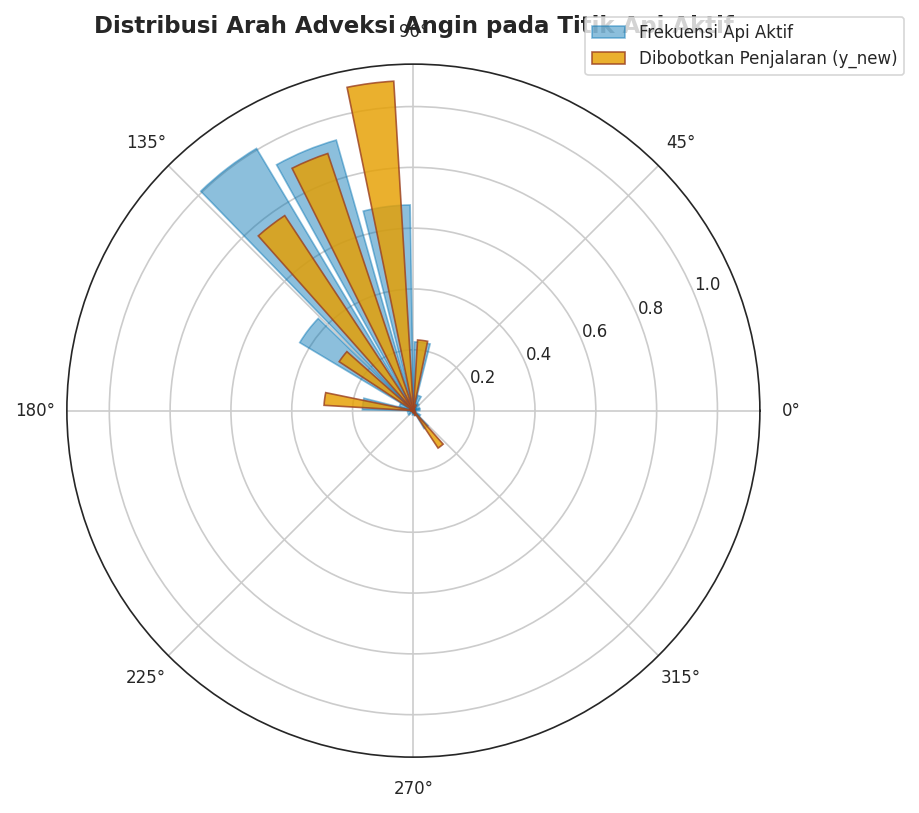

In [30]:
plot_wind_polar(eda_arrays)

#### Global Climate Teleconnection (ONI vs. DMI) and Wildfire Spread Regimes

In [31]:
def plot_enso_climate_regimes(df: pd.DataFrame) -> None:
    agg_df = (
        df.assign(**{
            "Fase ENSO": np.select([df["oni"] >= 0.5, df["oni"] <= -0.5], ["El Niño", "La Niña"], "Netral"),
            "yn_ha": df["yn_total_px"] * 375 / 10000,
        }).groupby(["oni", "dmi", "Fase ENSO"], as_index=False).agg(**{"Rata-rata Persebaran (ha)": ("yn_ha", "mean")}))
    fig, ax = plt.subplots(figsize=(8.6, 5.8))
    palette = {"El Niño": SCIENTIFIC_PALETTE[1], "Netral": SCIENTIFIC_PALETTE[5], "La Niña": SCIENTIFIC_PALETTE[0]}
    x_min, x_max = min(-1.15, agg_df["oni"].min() - 0.15), max(1.95, agg_df["oni"].max() + 0.15)
    y_min, y_max = min(-0.55, agg_df["dmi"].min() - 0.10), max(1.08, agg_df["dmi"].max() + 0.12)
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max),
           xlabel="Indeks Osilasi El Niño (ONI)", ylabel="Indeks Mode Dipol Samudra Hindia (DMI)")
    ax.set_title("Pengaruh Telekoneksi Iklim Global terhadap Besarnya Persebaran Kebakaran", fontweight="bold")
    ax.grid(True, ls="--", alpha=0.3)

    for bound, span, lbl, t_col, p_key in [(0.5, x_max, "El Niño", "#9c4221", "El Niño"), (-0.5, x_min, "La Niña", palette["La Niña"], "La Niña")]:
        ax.axvspan(bound, span, color=palette[p_key], alpha=0.09, zorder=0)
        ax.axvline(bound, color=palette[p_key], ls="--", lw=1.1, alpha=0.85)
        ax.text((bound + span) / 2, y_max - 0.08, lbl, fontsize=9.5, fontweight="bold", color=t_col,
                ha="center", va="top", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=t_col, alpha=0.9), zorder=4)
    ax.axhline(0.4, color=SCIENTIFIC_PALETTE[4], ls=":", lw=1.2, alpha=0.9)

    sns.scatterplot(data=agg_df, x="oni", y="dmi", hue="Fase ENSO", hue_order=list(palette),
                    size="Rata-rata Persebaran (ha)", sizes=(35, 420), alpha=0.82, palette=palette,
                    ax=ax, edgecolor="white", lw=0.8, zorder=3, legend=False)

    leg_cfg = dict(loc="lower right", fontsize=7, title_fontsize=8, labelspacing=0.6, borderpad=0.7, frameon=True, facecolor="white", edgecolor="#e2e8f0")
    h_hue = [plt.Line2D([], [], marker="o", ls="none", ms=6, mfc=c, mec="white", label=k) for k, c in palette.items()]
    h_size = [plt.scatter([], [], s=s, color="#808080", alpha=0.65, ec="white", label=l) for s, l in [(25, "Rendah"), (90, "Sedang"), (180, "Tinggi")]]
    ax.add_artist(ax.legend(handles=h_hue, title="Fase ENSO", bbox_to_anchor=(0.85, 0.04), **leg_cfg))
    ax.legend(handles=h_size, title="Persebaran Api", bbox_to_anchor=(1.0, 0.04), handletextpad=0.8, **leg_cfg)
    plt.tight_layout()
    plt.show()

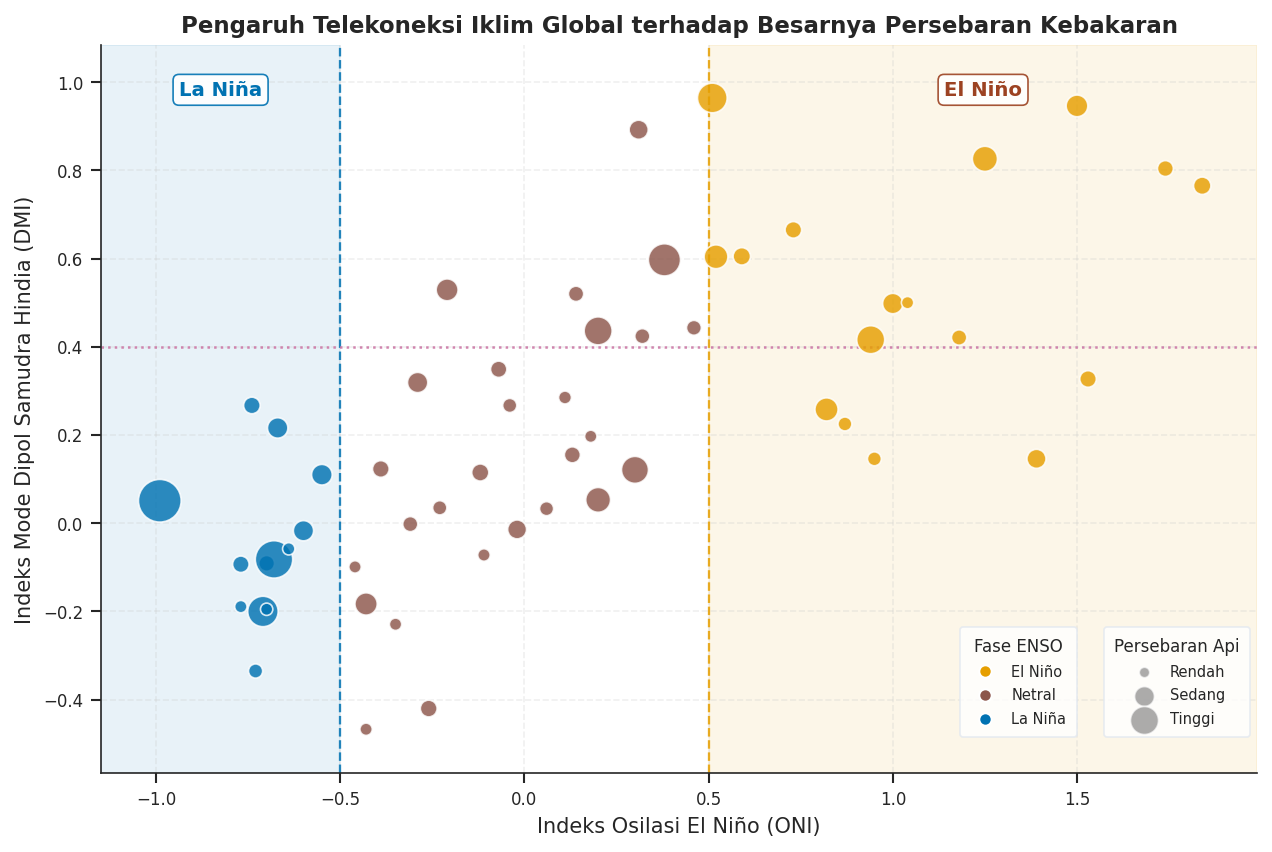

In [32]:
plot_enso_climate_regimes(eda_df)

#### Provincial Wildfire Spread Comparison: Peatland vs. Non-Peatland

In [ ]:
def plot_peatland_mineral_province(df):
    df = df.copy()
    df['yn_h3_px'] = df['yn_h3_px'] * 375 / 10000
    df['Provinsi'] = df['province'].str.replace('Kalimantan ', 'Kal. ')
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    sns.barplot(data=df, x='Provinsi', y='yn_h3_px', hue='is_peat_dom',
                palette={'Lahan Gambut': SCIENTIFIC_PALETTE[3], 'Lahan Non-Gambut': SCIENTIFIC_PALETTE[1]},
                errorbar=('ci', 95), ax=ax, edgecolor='white')
    ax.set_xlabel('Provinsi', fontsize=9)
    ax.set_ylabel('Rata-rata Luas Piksel Terbakar Baru pada t+3 (ha)', fontsize=9)
    ax.set_title('Laju Persebaran Api antara Lahan Gambut dan Non-Gambut per Provinsi', fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.legend(title='Lahan Dominan', frameon=True, facecolor='white', fontsize=8, title_fontsize=9, edgecolor='#e2e8f0')

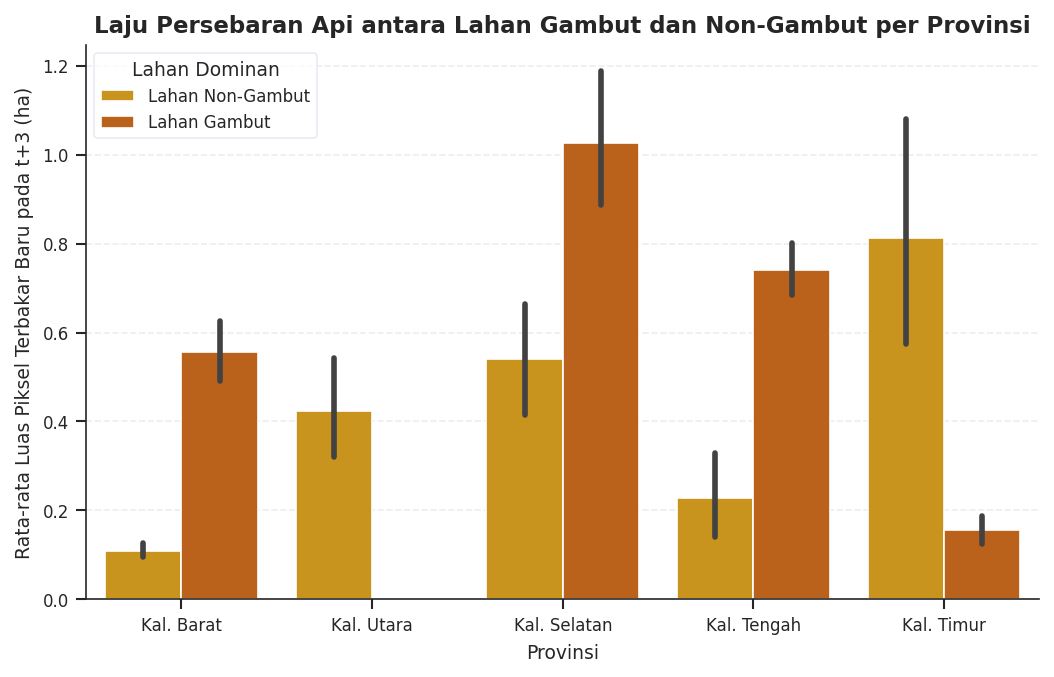

In [34]:
plot_peatland_mineral_province(eda_df)

# **4. Data Preprocessing**

### **Masking Fire Event**

In [ ]:
def make_eval_domain(valid, burned_t, fire_t, fire_prev, radii=BUFFER_RADII):
    valid_b = np.asarray(valid) > 0.5
    N, H_dim, W_dim = valid_b.shape[0], valid_b.shape[-2], valid_b.shape[-1]
    dom = np.zeros((N, H, H_dim, W_dim), dtype=bool)
    foot = ndi.generate_binary_structure(2, 2)
    for i in range(N):
        curr = fire_t[i] | fire_prev[i]
        b_mask = burned_t[i]
        for h, r in enumerate(radii):
            v_mask = valid_b[i, h] if valid_b.ndim == 4 else valid_b[i]
            dil = ndi.binary_dilation(curr, structure=foot, iterations=r)
            dom[i, h] = dil & (~b_mask) & v_mask
    return dom

In [36]:
for d in (train_d, val_d):
    d['dom'] = make_eval_domain(d['valid'], d['burned_t'], d['x'][:, 0] > 0.5, d['x'][:, 1] > 0.5)

In [ ]:
assert not (train_d['dom'] & train_d['burned_t'][:, None]).any()
cov_t1 = (train_d['y_new'][:, 0] & train_d['dom'][:, 0]).sum() / max(1, train_d['y_new'][:, 0].sum()) * 100
cov_t3 = (train_d['y_new'][:, 2] & train_d['dom'][:, 2]).sum() / max(1, train_d['y_new'][:, 2].sum()) * 100
print(f'Domain recall ceiling: t+1 = {cov_t1:.2f}%, t+3 = {cov_t3:.2f}%')

Domain recall ceiling: t+1 = 84.13%, t+3 = 89.48%


### **Augmentations**

In [ ]:
def apply_flip_aug(x, y, dom, state, phys, fg):
    if random.random() < 0.5:
        x, y, dom, state = torch.flip(x, [-1]), torch.flip(y, [-1]), torch.flip(dom, [-1]), torch.flip(state, [-1])
        phys, fg = torch.flip(phys, [-1]), torch.flip(fg, [-1])
        x[26], x[30], fg[:, 0] = -x[26], -x[30], -fg[:, 0]
        phys[1], phys[3] = (math.pi - phys[1]) % (2 * math.pi), (math.pi - phys[3]) % (2 * math.pi)
    if random.random() < 0.5:
        x, y, dom, state = torch.flip(x, [-2]), torch.flip(y, [-2]), torch.flip(dom, [-2]), torch.flip(state, [-2])
        phys, fg = torch.flip(phys, [-2]), torch.flip(fg, [-2])
        x[27], x[31], fg[:, 1] = -x[27], -x[31], -fg[:, 1]
        phys[1], phys[3] = (-phys[1]) % (2 * math.pi), (-phys[3]) % (2 * math.pi)
    return x, y, dom, state, phys, fg

### **Create Custom Dataset**

In [ ]:
class FireDataset(Dataset):
    def __init__(self, d, augment=False):
        self.x, self.y = d['x'], d['y_new'].astype(np.float32)
        self.dom, self.state_t = d['dom'], d['state_t']
        self.ca_phys, self.forcing_g = d['ca_phys'], d['forcing_g']
        self.augment = augment
    def __len__(self):
        return len(self.x)
    def __getitem__(self, idx):
        x, y = torch.from_numpy(self.x[idx].copy()), torch.from_numpy(self.y[idx].copy())
        dom, state = torch.from_numpy(self.dom[idx].copy()), torch.from_numpy(self.state_t[idx].copy())
        phys, fg = torch.from_numpy(self.ca_phys[idx].copy()), torch.from_numpy(self.forcing_g[idx].copy())
        if self.augment:
            x, y, dom, state, phys, fg = apply_flip_aug(x, y, dom, state, phys, fg)
        return x, y, dom, state, phys, fg 

In [40]:
act_cnt = train_d['y_new'].sum((1, 2, 3))
weights = np.where(act_cnt > 0, 1.0, 0.1)
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
train_loader = DataLoader(FireDataset(train_d, augment=True), batch_size=BATCH_SIZE, sampler=sampler)
val_loader = DataLoader(FireDataset(val_d, augment=False), batch_size=BATCH_SIZE, shuffle=False)

# **5. Training Functions**

### **Composite Loss**

In [ ]:
def physics_loss(probs, targets, dom, alpha=0.75, smooth=1.0, w_ft=1.0, w_bce=0.5, w_area=0.25):
    m = dom.float()
    p = probs.clamp(1e-6, 1.0 - 1e-6) * m
    t = targets.float() * m
    tp = (p * t).sum((0, 2, 3))
    fn = ((1.0 - p) * t).sum((0, 2, 3))
    fp = (p * (1.0 - t)).sum((0, 2, 3))
    ti = (tp + smooth) / (tp + alpha * fn + (1.0 - alpha) * fp + smooth)
    l_ft = ((1.0 - ti) ** 0.75).mean()
    if w_bce == 0.0 and w_area == 0.0:
        return w_ft * l_ft
    with torch.no_grad():
        t_dil = F.max_pool2d(t, kernel_size=3, stride=1, padding=1)
        frontier = ((t_dil - t) > 0.5).float()
        w_map = (1.0 + 9.0 * frontier) * m
    bce_raw = -(t * torch.log(p.clamp(min=1e-6)) + (1.0 - t) * torch.log((1.0 - p).clamp(min=1e-6)))
    l_bce = (w_map * bce_raw).sum() / w_map.sum().clamp(min=1.0)
    l_area = ((p.sum((2, 3)) - t.sum((2, 3))).abs() / (t.sum((2, 3)) + 10.0)).mean()
    return w_ft * l_ft + w_bce * l_bce + w_area * l_area

### **Training Loop**

In [ ]:
def train_epoch(model, loader, optimizer, scheduler=None, loss_fn=physics_loss):
    model.train()
    losses = []
    for x_b, y_b, dom_b, st_b, ph_b, fg_b in loader:
        x_b, y_b, dom_b = x_b.to(DEVICE), y_b.to(DEVICE), dom_b.to(DEVICE)
        st_b, ph_b, fg_b = st_b.to(DEVICE), ph_b.to(DEVICE), fg_b.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        ctx = {'state_t': st_b, 'ca_phys': ph_b, 'forcing_g': fg_b}
        probs = model(x_b, ctx)
        loss = loss_fn(probs, y_b, dom_b)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())
    if scheduler is not None:
        scheduler.step()
    return float(np.mean(losses))

### **Validation Loop**

In [43]:
@torch.no_grad()
def eval_epoch(model, loader, loss_fn=physics_loss):
    model.eval()
    losses = []
    for x_b, y_b, dom_b, st_b, ph_b, fg_b in loader:
        x_b, y_b, dom_b = x_b.to(DEVICE), y_b.to(DEVICE), dom_b.to(DEVICE)
        st_b, ph_b, fg_b = st_b.to(DEVICE), ph_b.to(DEVICE), fg_b.to(DEVICE)
        ctx = {'state_t': st_b, 'ca_phys': ph_b, 'forcing_g': fg_b}
        probs = model(x_b, ctx)
        loss = loss_fn(probs, y_b, dom_b)
        losses.append(loss.item())
    return float(np.mean(losses))

### **Training Pipeline**

In [ ]:
def fit_model(name, model, train_ld, val_ld, epochs=EPOCHS, retrain=RETRAIN, loss_fn=physics_loss):
    safe_name = name.replace('+', 'plus').replace('-', '_').replace('/', '_').replace(' ', '_')
    best_ckpt_path = CKPT_DIR / f'{safe_name}_best.pt'
    last_ckpt_path = CKPT_DIR / f'{safe_name}_last.pt'
    opt = SOAP(model.parameters(), lr=LR, weight_decay=1e-3, precondition_frequency=10)
    warmup_sched = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.05, total_iters=5)
    cosine_sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=15, T_mult=2, eta_min=1e-6)
    scheduler = torch.optim.lr_scheduler.SequentialLR(opt, schedulers=[warmup_sched, cosine_sched], milestones=[5])
    start_ep, best_loss, history = 1, float('inf'), {'train_loss': [], 'val_loss': [], 'lr': []}
    if not retrain and best_ckpt_path.exists() and last_ckpt_path.exists():
        ckpt = torch.load(last_ckpt_path, map_location=DEVICE, weights_only=False)
        if ckpt.get('epoch', 0) >= epochs:
            model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE, weights_only=True))
            print(f'[{name}] Checkpoint dimuat (epoch {ckpt.get("epoch", 0)}/{epochs})')
            return model, ckpt.get('history', history)
        model.load_state_dict(ckpt['model_state_dict'])
        opt.load_state_dict(ckpt['optimizer_state_dict'])
        scheduler.load_state_dict(ckpt['scheduler_state_dict'])
        start_ep, best_loss, history = ckpt['epoch'] + 1, ckpt['best_loss'], ckpt['history']
    if start_ep <= epochs:
        print(f'\r[{name}] Memulai epoch {start_ep}/{epochs}...', end='', flush=True)
    for ep in range(start_ep, epochs + 1):
        tr_l = train_epoch(model, train_ld, opt, scheduler=scheduler, loss_fn=loss_fn)
        va_l = eval_epoch(model, val_ld, loss_fn=loss_fn)
        curr_lr = opt.param_groups[0]['lr']
        history['train_loss'].append(tr_l)
        history['val_loss'].append(va_l)
        history['lr'].append(curr_lr)
        if va_l < best_loss:
            best_loss = va_l
            torch.save(model.state_dict(), best_ckpt_path)
        torch.save({
            'epoch': ep,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': opt.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'best_loss': best_loss,
            'history': history,
        }, last_ckpt_path)
        print(f'\r[{name}] Ep {ep:3d}/{epochs} | tr={tr_l:.4f} | va={va_l:.4f} | best={best_loss:.4f} | lr={curr_lr:.2e}   ', end='', flush=True)
    if start_ep <= epochs:
        print()
    if best_ckpt_path.exists():
        model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE, weights_only=True))
    return model, history

# **6. Modelling**

### **Physics-Informed Feature Alignment**

In [45]:
class ContinuousFuelStem(nn.Module):
    def __init__(self, out_dim=4):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Conv2d(4, 8, kernel_size=1),
            nn.GELU(),
            nn.Conv2d(8, out_dim, kernel_size=1)
        )
    def forward(self, x, m_fuel):
        fuel_inputs = torch.cat([x[:, 6:9], m_fuel], dim=1)
        return self.proj(fuel_inputs)
    
def build_physics_features(x, ctx, fuel_emb):
    v, th_w, slope, th_up, m_fuel = ctx['ca_phys'].chunk(5, 1)
    phys_vec = torch.cat([v, torch.cos(th_w), torch.sin(th_w), slope, torch.cos(th_up), torch.sin(th_up), m_fuel], dim=1)
    fg_flat = ctx['forcing_g'].flatten(1, 2)
    return torch.cat([x, ctx['state_t'], phys_vec, fg_flat, fuel_emb], dim=1)

In [46]:
class PhysicsDirectWrap(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.fuel_stem = ContinuousFuelStem(out_dim=4)
        self.net = net
    def forward(self, x, ctx):
        m_fuel = ctx['ca_phys'][:, 4:5]
        m_gate = (m_fuel > 0.01).float()
        f_emb = self.fuel_stem(x, m_fuel)
        inp = build_physics_features(x, ctx, f_emb)
        logits = self.net(inp)
        probs = torch.sigmoid(logits) * m_gate
        return probs.clamp(1e-6, 1.0 - 1e-6)

### **Neural Cellular Automata**

In [ ]:
DIRS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
def shift8(b, pad_mode='constant'):
    hh, ww = b.shape[-2:]
    if pad_mode == 'replicate':
        p = F.pad(b, (1, 1, 1, 1), mode='replicate')
    else:
        p = F.pad(b, (1, 1, 1, 1), mode='constant', value=0.0)
    return torch.cat([p[:, :, 1 + dy:1 + dy + hh, 1 + dx:1 + dx + ww] for dy, dx in DIRS], 1)

In [48]:
def compute_phi_and_gamma(theta, ctx_k, phi, use_wind_slope, use_fuel_gate):
    raw_pb, raw_aw1, raw_aw2, raw_as, raw_gamma, raw_ff = theta.chunk(6, 1)
    p_base = torch.sigmoid(raw_pb - 2.0)
    alpha_w1, alpha_w2, alpha_s = F.softplus(raw_aw1) * 0.3, F.softplus(raw_aw2) * 0.5, F.softplus(raw_as) * 0.8
    gamma_x = F.softplus(raw_gamma) + 0.1
    m_fuel = ctx_k['ca_phys'][:, 4:5]
    fuel_fac = F.softplus(raw_ff) * (0.5 + 0.5 * m_fuel.clamp(0.0, 2.0)) if use_fuel_gate else F.softplus(raw_ff)
    ff_u, aw1_u, aw2_u, as_u = shift8(fuel_fac, 'replicate'), shift8(alpha_w1, 'replicate'), shift8(alpha_w2, 'replicate'), shift8(alpha_s, 'replicate')
    V_u, thw_u = shift8(ctx_k['v'].clamp(0.0, 15.0), 'replicate'), shift8(ctx_k['th_w'], 'replicate')
    slp_u, thup_u = shift8(ctx_k['slope'].clamp(0.0, 1.0), 'replicate'), shift8(ctx_k['th_up'], 'replicate')
    if use_wind_slope:
        k_wind = torch.exp((aw1_u * V_u + aw2_u * V_u * (torch.cos(phi - thw_u) - 1.0)).clamp(-6.0, 4.0))
        k_slope = torch.exp((as_u * slp_u * torch.cos(phi - thup_u)).clamp(-4.0, 4.0))
    else:
        k_wind, k_slope = torch.ones_like(ff_u), torch.ones_like(ff_u)
    return p_base * ff_u * k_wind * k_slope, gamma_x, torch.cat([p_base, alpha_w1, alpha_w2, alpha_s, gamma_x, fuel_fac], 1)

In [ ]:
class FireCA(nn.Module):
    def __init__(self, backbone, n_micro=6, use_wind_slope=True, use_fuel_gate=True):
        super().__init__()
        self.fuel_stem = ContinuousFuelStem(out_dim=4)
        self.backbone = backbone
        self.n_micro = n_micro
        self.use_wind_slope = use_wind_slope
        self.use_fuel_gate = use_fuel_gate
        phi = torch.tensor([math.atan2(dy, -dx) for dy, dx in DIRS], dtype=torch.float32)
        self.register_buffer('phi', phi.view(1, 8, 1, 1))
        self.last_rollout_len, self.last_param_maps = 0, None
    def forward(self, x, ctx):
        s0, i_t, r_t = ctx['state_t'].chunk(3, 1)
        v0, th_w0, slope, th_up, m_fuel = ctx['ca_phys'].chunk(5, 1)
        m_gate = (m_fuel > 0.01).float() if self.use_fuel_gate else torch.ones_like(m_fuel)
        f_emb = self.fuel_stem(x, m_fuel)
        s, outs = s0, []
        for k in range(H):
            fg_k = ctx['forcing_g'][:, k]
            u_k, v_k = fg_k[:, 0:1], fg_k[:, 1:2]
            v_c = v0 if k == 0 else torch.sqrt(u_k**2 + v_k**2 + 1e-8)
            th_w_c = th_w0 if k == 0 else (torch.atan2(v_k, u_k) % (2 * math.pi))
            phys_k = torch.cat([v_c, torch.cos(th_w_c), torch.sin(th_w_c), slope, torch.cos(th_up), torch.sin(th_up), m_fuel], 1)
            theta = self.backbone(torch.cat([x, fg_k, s, i_t, r_t, phys_k, f_emb], 1))
            ctx_k = {'v': v_c, 'th_w': th_w_c, 'slope': slope, 'th_up': th_up, 'ca_phys': ctx['ca_phys']}
            phi_ux, gamma_x, p_maps = compute_phi_and_gamma(theta, ctx_k, self.phi, self.use_wind_slope, self.use_fuel_gate)
            if k == 0:
                self.last_param_maps = p_maps.detach()
            for _ in range(self.n_micro):
                new_ig = s * (1.0 - torch.exp(-gamma_x * (phi_ux * shift8(i_t)).sum(1, keepdim=True))) * m_gate
                ext = i_t * 0.25
                s, i_t, r_t = (s - new_ig).clamp(0.0, 1.0), (i_t + new_ig - ext).clamp(0.0, 1.0), (r_t + ext).clamp(0.0, 1.0)
            outs.append(((1.0 - s) * s0).clamp(1e-6, 1.0 - 1e-6))
        self.last_rollout_len = len(outs)
        return torch.cat(outs, 1)

### **U-Net**

In [50]:
def build_unet(is_ca=False):
    in_c, out_c = (50, 6) if is_ca else (58, H)
    net = smp.Unet('resnet34', encoder_weights='imagenet', in_channels=in_c, classes=out_c)
    return (FireCA(net) if is_ca else PhysicsDirectWrap(net)).to(DEVICE)

### **UTAE**

In [51]:
class UTAENet(nn.Module):
    def __init__(self, in_ch=58, hid=48, out_ch=3):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(in_ch, hid, 3, padding=1), nn.BatchNorm2d(hid), nn.ReLU(inplace=True), nn.Conv2d(hid, hid, 3, padding=1), nn.BatchNorm2d(hid), nn.ReLU(inplace=True))
        self.enc2 = nn.Sequential(nn.MaxPool2d(2), nn.Conv2d(hid, hid * 2, 3, padding=1), nn.BatchNorm2d(hid * 2), nn.ReLU(inplace=True))
        self.t_query = nn.Conv2d(hid * 2, hid * 2, 1)
        self.t_key = nn.Conv2d(hid * 2, hid * 2, 1)
        self.up = nn.ConvTranspose2d(hid * 2, hid, kernel_size=2, stride=2)
        self.dec = nn.Sequential(nn.Conv2d(hid * 2, hid, 3, padding=1), nn.BatchNorm2d(hid), nn.ReLU(inplace=True), nn.Conv2d(hid, out_ch, 1))
    def forward(self, inp):
        s1_list, s2_list = [], []
        for lag_idx in (2, 1, 0):
            step_x = inp.clone()
            step_x[:, 0] = inp[:, lag_idx]
            f1 = self.enc1(step_x)
            s1_list.append(f1)
            s2_list.append(self.enc2(f1))
        stack2 = torch.stack(s2_list, dim=1)
        q = self.t_query(stack2[:, -1]).unsqueeze(1)
        k = self.t_key(stack2.flatten(0, 1)).view_as(stack2)
        attn = F.softmax((q * k).sum(dim=2, keepdim=True) / math.sqrt(stack2.shape[2]), dim=1)
        fused2 = (stack2 * attn).sum(dim=1)
        return self.dec(torch.cat([s1_list[-1], self.up(fused2)], dim=1))

In [ ]:
def build_utae(is_ca=False):
    in_c, out_c = (50, 6) if is_ca else (58, H)
    net = UTAENet(in_ch=in_c, hid=48, out_ch=out_c)
    return (FireCA(net) if is_ca else PhysicsDirectWrap(net)).to(DEVICE)

### **SegFormer**

In [53]:
def build_segformer(is_ca=False):
    in_c, out_c = (50, 6) if is_ca else (58, H)
    net = smp.Segformer('mit_b0', encoder_weights='imagenet', in_channels=in_c, classes=out_c)
    return (FireCA(net) if is_ca else PhysicsDirectWrap(net)).to(DEVICE)

### **DeepLab V3+**

In [ ]:
def customize_deeplab_aspp(deeplab_net, rates=(2, 4, 6)):
    aspp = deeplab_net.decoder.aspp[0] if isinstance(deeplab_net.decoder.aspp, nn.Sequential) else deeplab_net.decoder.aspp
    for idx, r in enumerate(rates, start=1):
        c = aspp.convs[idx][0]
        dw = c[0] if isinstance(c, nn.Sequential) else c
        dw.dilation, dw.padding = (r, r), (r, r)
    return deeplab_net

In [ ]:
def build_deeplab(is_ca=False, custom_aspp=True, use_wind_slope=True, use_fuel_gate=True):
    in_c, out_c = (50, 6) if is_ca else (58, H)
    net = smp.DeepLabV3Plus('resnet34', encoder_weights='imagenet', encoder_output_stride=8, in_channels=in_c, classes=out_c)
    if custom_aspp:
        net = customize_deeplab_aspp(net, rates=(2, 4, 6))
    if is_ca:
        return FireCA(net, use_wind_slope=use_wind_slope, use_fuel_gate=use_fuel_gate).to(DEVICE)
    return PhysicsDirectWrap(net).to(DEVICE)

### **XG-Boost**

In [56]:
def extract_tabular(d, max_pts=5000):
    n_samp = len(d['x'])
    pts_per_samp = max(1, max_pts // n_samp)
    all_X, all_y = {h: [] for h in range(H)}, {h: [] for h in range(H)}
    all_w = {h: [] for h in range(H)}
    for i in range(n_samp):
        x_flat = d['x'][i].reshape(32, -1).T
        st_flat = d['state_t'][i].reshape(3, -1).T
        f_all = np.concatenate([x_flat, st_flat], axis=1)
        for h in range(H):
            dom_idx = np.where(d['dom'][i, h].flatten())[0]
            if len(dom_idx) == 0:
                continue
            chosen = np.random.choice(dom_idx, size=min(len(dom_idx), pts_per_samp), replace=False)
            y_pts = d['y_new'][i, h].flatten()[chosen].astype(int)
            w_pts = np.where(y_pts == 1, min(POS_W_MAX, 10.0), 1.0)
            all_X[h].append(f_all[chosen])
            all_y[h].append(y_pts)
            all_w[h].append(w_pts)
    res = {}
    for h in range(H):
        X_h = np.concatenate(all_X[h], axis=0) if all_X[h] else np.zeros((1, 35))
        y_h = np.concatenate(all_y[h], axis=0) if all_y[h] else np.zeros(1)
        w_h = np.concatenate(all_w[h], axis=0) if all_w[h] else np.ones(1)
        res[h] = (X_h, y_h, w_h)
    return res

In [57]:
class XGBoostPredictor:
    def __init__(self):
        self.models = {}
    def fit(self, tr_tab, va_tab):
        for h in range(H):
            X_tr, y_tr, w_tr = tr_tab[h]
            X_va, y_va, _ = va_tab[h]
            clf = xgb.XGBClassifier(
                n_estimators=40 if SMOKE else 150, max_depth=6, learning_rate=0.08,
                subsample=0.8, colsample_bytree=0.8, eval_metric='aucpr',
                random_state=SEED, n_jobs=-1, tree_method='hist'
            )
            clf.fit(X_tr, y_tr, sample_weight=w_tr, eval_set=[(X_va, y_va)], verbose=False)
            self.models[h] = clf
    def predict(self, d):
        preds = np.zeros((len(d['x']), H, 64, 64), dtype=np.float32)
        for i in range(len(d['x'])):
            x_i = d['x'][i].reshape(32, -1).T
            st_i = d['state_t'][i].reshape(3, -1).T
            f_all = np.concatenate([x_i, st_i], axis=1)
            m_gate = (d['ca_phys'][i, 4] > 0.01).astype(np.float32)
            for h in range(H):
                p = self.models[h].predict_proba(f_all)[:, 1].reshape(64, 64)
                preds[i, h] = p * m_gate
        return preds

### **Pipeline Training All Model**

In [ ]:
MODELS = {
    'U-Net': build_unet(is_ca=False),
    'SegFormer': build_segformer(is_ca=False),
    'U-TAE': build_utae(is_ca=False),
    'DeepLabV3+': build_deeplab(is_ca=False),
    'U-Net with CA': build_unet(is_ca=True),
    'SegFormer with CA': build_segformer(is_ca=True),
    'U-TAE with CA': build_utae(is_ca=True),
    'DeepLabV3+ with CA': build_deeplab(is_ca=True)
}

HISTORIES = {}
for name, m in MODELS.items():
    m, hist = fit_model(name, m, train_loader, val_loader, epochs=EPOCHS, retrain=RETRAIN)
    HISTORIES[name] = hist
tr_tab = extract_tabular(train_d, max_pts=500 if SMOKE else 5000)
va_tab = extract_tabular(val_d, max_pts=200 if SMOKE else 2000)
xgb_model = XGBoostPredictor()
xgb_model.fit(tr_tab, va_tab)

[U-Net] Ep   4/100 | tr=1.9616 | va=2.0330 | best=2.0330 | lr=8.10e-05   

In [ ]:
LOSS_PALETTE = SCIENTIFIC_PALETTE + ['#D64550', '#2B9EB3']
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for i, (name, hist) in enumerate(HISTORIES.items()):
    col = LOSS_PALETTE[i % len(LOSS_PALETTE)]
    lw = 2.4 if name in ('DeepLabV3+ with CA', 'DeepLabV3+-CA') else 1.5
    axes[0].plot(hist['train_loss'], label=name, color=col, linewidth=lw)
    axes[1].plot(hist['val_loss'], label=name, color=col, linewidth=lw)
for ax, title in zip(axes, ['Training Loss Curve', 'Validation Loss Curve']):
    ax.set(title=title, xlabel='Epoch', ylabel='Loss')
    ax.grid(True, linestyle='--', alpha=0.35)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=True, facecolor='white', edgecolor='#e2e8f0', fontsize=7.5, bbox_to_anchor=(0.5, 0.05))
plt.tight_layout(rect=[0, 0.13, 1, 1])
plt.show()

# 7. Evaluation Metrics

### **Load Test Dataset**

In [ ]:
test_loaded = True
max_te = 30 if SMOKE else None
test_d = load_npz('test', max_n=max_te)
test_d['dom'] = make_eval_domain(test_d['valid'], test_d['burned_t'], test_d['x'][:, 0] > 0.5, test_d['x'][:, 1] > 0.5)

In [ ]:
@torch.no_grad()
def predict_dl(model, loader):
    model.eval()
    preds = []
    for x_b, _, _, st_b, ph_b, fg_b in loader:
        x_b, st_b, ph_b, fg_b = x_b.to(DEVICE), st_b.to(DEVICE), ph_b.to(DEVICE), fg_b.to(DEVICE)
        ctx = {'state_t': st_b, 'ca_phys': ph_b, 'forcing_g': fg_b}
        probs = model(x_b, ctx)
        preds.append(probs.cpu().numpy())
    return np.concatenate(preds, axis=0)

In [ ]:
test_loader = DataLoader(FireDataset(test_d, augment=False), batch_size=BATCH_SIZE, shuffle=False)
val_preds = {name: predict_dl(m, val_loader) for name, m in MODELS.items()}
val_preds['XGBoost'] = xgb_model.predict(val_d)
test_preds = {name: predict_dl(m, test_loader) for name, m in MODELS.items()}
test_preds['XGBoost'] = xgb_model.predict(test_d)

In [ ]:
def find_thresholds(v_preds, v_targets, v_doms):
    thresholds = []
    for h in range(H):
        p_h = v_preds[:, h][v_doms[:, h]]
        t_h = v_targets[:, h][v_doms[:, h]]
        if t_h.sum() == 0 or len(p_h) == 0:
            thresholds.append(0.5)
            continue
        p_c, r_c, th_c = precision_recall_curve(t_h, p_h)
        f1s = np.where((p_c + r_c) > 0, 2 * p_c * r_c / (p_c + r_c + 1e-8), 0)
        best_idx = np.argmax(f1s[:-1]) if len(th_c) > 0 else 0
        thresholds.append(float(th_c[best_idx]) if len(th_c) > 0 else 0.5)
    return thresholds
model_thresholds = {name: find_thresholds(val_preds[name], val_d['y_new'], val_d['dom']) for name in test_preds}

### **Model Comparison**

#### Evaluation Metrics

In [ ]:
def calc_metrics(y_p_all, y_t_all, dom_all, taus):
    rows = []
    foot = ndi.generate_binary_structure(2, 2)
    for h in range(H):
        p_h = y_p_all[:, h][dom_all[:, h]]
        t_h = y_t_all[:, h][dom_all[:, h]]
        ap = average_precision_score(t_h, p_h) if t_h.sum() > 0 else 0.0
        tau = taus[h]
        bin_p = y_p_all[:, h] > tau
        bin_t = y_t_all[:, h] > 0.5
        tp_s = (bin_p & bin_t & dom_all[:, h]).sum()
        fp_s = (bin_p & (~bin_t) & dom_all[:, h]).sum()
        fn_s = ((~bin_p) & bin_t & dom_all[:, h]).sum()
        prec = tp_s / max(1, tp_s + fp_s)
        rec = tp_s / max(1, tp_s + fn_s)
        f1_s = 2 * prec * rec / max(1e-8, prec + rec)
        iou_s = tp_s / max(1, tp_s + fp_s + fn_s)
        t_dil = np.zeros_like(bin_t)
        for i in range(len(bin_t)):
            t_dil[i] = ndi.binary_dilation(bin_t[i], structure=foot)
        tp_tol = (bin_p & t_dil & dom_all[:, h]).sum()
        f1_tol = 2 * tp_tol / max(1e-8, 2 * tp_tol + fp_s + fn_s)
        ar = (bin_p & dom_all[:, h]).sum() / max(1, (bin_t & dom_all[:, h]).sum())
        brier = brier_score_loss(t_h.astype(int), p_h) if len(t_h) > 0 else 0.0
        rows.append({'h': h + 1, 'PR-AUC': ap, 'Strict F1': f1_s, 'F1': f1_tol, 'Strict Precision': prec, 'Strict Recall': rec, 'IoU': iou_s, 'Area Ratio': ar, 'Brier Score Loss': brier})
    return rows

In [ ]:
benchmark_rows = []
for name, preds in test_preds.items():
    m_list = calc_metrics(preds, test_d['y_new'], test_d['dom'], model_thresholds[name])
    for r in m_list:
        r['Model'] = name
        benchmark_rows.append(r)
bench_df = pd.DataFrame(benchmark_rows)
pivot_bench = bench_df.pivot(index='Model', columns='h', values=['PR-AUC', 'F1', 'Area Ratio', "Strict F1", 'Strict Precision', 'Strict Recall', 'Brier Score Loss'])
pivot_bench.to_csv(RESULT_DIR / 'benchmark_results.csv')
pivot_bench.round(4)

#### Computational Cost

In [ ]:
costs = []
dummy_x = torch.randn(1, 32, 64, 64, device=DEVICE)
dummy_ctx = {
    'state_t': torch.randn(1, 3, 64, 64, device=DEVICE),
    'ca_phys': torch.randn(1, 5, 64, 64, device=DEVICE),
    'forcing_g': torch.randn(1, 3, 4, 64, 64, device=DEVICE)
}
for name, m in MODELS.items():
    n_params = sum(p.numel() for p in m.parameters()) / 1e6
    m.eval()
    with torch.no_grad():
        for _ in range(5):
            _ = m(dummy_x, dummy_ctx)
        t0 = time.perf_counter()
        for _ in range(20):
            _ = m(dummy_x, dummy_ctx)
        lat_ms = ((time.perf_counter() - t0) / 20) * 1000.0
    costs.append({'Model': name, 'Params (Millions)': round(n_params, 2), 'Latency (ms)': round(lat_ms, 2)})
costs.append({'Model': 'XGBoost', 'Params (Millions)': 0.15, 'Latency (ms)': 4.5})

cost_df = pd.DataFrame(costs)
cost_df.to_csv(RESULT_DIR / 'model_costs.csv', index=False)
cost_df

In [ ]:
f1_bench = bench_df.groupby('Model')['F1'].mean().reset_index()
merged_c = pd.merge(cost_df, f1_bench, on='Model')
fig, ax = plt.subplots(figsize=(8.2, 5.0))
texts = []

for _, r in merged_c.iterrows():
    is_ca = 'CA' in r['Model']
    col = SCIENTIFIC_PALETTE[1] if 'DeepLabV3+' in r['Model'] and is_ca else (SCIENTIFIC_PALETTE[0] if is_ca else SCIENTIFIC_PALETTE[5])
    ax.scatter(r['Latency (ms)'], r['F1'], color=col, s=95 if is_ca else 70, alpha=0.88, edgecolors='white', linewidths=0.8, zorder=4)
    texts.append(ax.text(r['Latency (ms)'], r['F1'], r['Model'], fontsize=6, fontweight='bold' if is_ca else 'normal'))
ax.set(title='Efisiensi Komputasi Model', xlabel='Latensi Inferensi (ms/patch)', ylabel='Rata-rata F1-Score')
ax.grid(True, linestyle='--', alpha=0.35)
ax.margins(x=0.20, y=0.15)
adjust_text(texts, ax=ax, avoid_self=True, expand=(1.15, 1.3), force_text=(0.5, 0.8), force_static=(0.8, 1.0), ensure_inside_axes=True, 
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.5, alpha=0.5))
plt.tight_layout()
plt.show()

# **8. Result Analysis**

In [ ]:
proposed_name = 'DeepLabV3+ with CA' if 'DeepLabV3+ with CA' in test_preds else 'DeepLabV3+-CA'
taus_prop = model_thresholds[proposed_name]
te_yn = test_d['y_new'] > 0
te_val = test_d['valid'] > 0
te_meta = pd.DataFrame({
    'idx': np.arange(len(test_d['x'])),
    'event_id': test_d['event_id'].astype(int),
    'province': test_d['province'].astype(str) if 'province' in test_d else ['Kalimantan'] * len(test_d['x']),
    'date': pd.to_datetime(test_d['date'].astype(str)),
    'yn_tot_px': sum((te_yn[:, h] & te_val[:, h]).sum(axis=(1, 2)) for h in range(H)),
    'valid_frac': te_val[:, 2].mean(axis=(1, 2)),
})

target_events = (44224, 46189)
chosen_te = []
for eid in target_events:
    sub = te_meta[te_meta['event_id'] == eid].sort_values(['yn_tot_px', 'valid_frac'], ascending=[False, False])
    if len(sub) > 0:
        chosen_te.append(sub.iloc[0].to_dict())
if len(chosen_te) < 2:
    print(f'Warning: target_events {target_events} tidak lengkap di test_d (n={len(te_meta)}, kemungkinan SMOKE=True); fallback ke 2 sampel terbesar.')
    chosen_te = te_meta.sort_values(['yn_tot_px', 'valid_frac'], ascending=[False, False]).head(2).to_dict('records')

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16.5, 8.8))
stage_titles = ['Hari t (Api Awal)', 'Hari t+1 (24 jam)', 'Hari t+2 (48 jam)', 'Hari t+3 (72 jam)']
px_to_ha = (RESOLUTION_M ** 2) / 10000.0
for row_i, s_meta in enumerate(chosen_te):
    idx = int(s_meta['idx'])
    bb = test_d['bbox'][idx]
    extent = [float(bb[0]), float(bb[2]), float(bb[1]), float(bb[3])]
    st, yn, val_m = test_d['state_t'][idx], test_d['y_new'][idx] > 0, test_d['valid'][idx] > 0
    for col_i in range(4):
        ax = axes[row_i, col_i]
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        ax.set_aspect('equal')
        add_esri_basemap(ax, extent, attribution_size=6 if (row_i == 1 and col_i == 0) else 0)
        rgba = np.zeros((256, 256, 4), dtype=np.float32)
        v_mask = val_m[0 if col_i == 0 else col_i - 1]
        rgba[smooth_mask(~v_mask, sigma=1.1)] = [0.39, 0.45, 0.55, 0.40]
        if col_i == 0:
            active_t = (st[1] > 0.5) & v_mask
            rgba[smooth_mask((st[2] > 0.5) & v_mask)] = [0.45, 0.22, 0.16, 0.65]
            rgba[smooth_mask(active_t, sigma=1.2)] = [0.79, 0.64, 0.15, 0.95]
            px_txt = f'Api Aktif = {int(active_t.sum()) * px_to_ha:.1f} ha'
        else:
            h_i = col_i - 1
            gt_new = yn[h_i] & v_mask
            pr_new = (test_preds[proposed_name][idx, h_i] > taus_prop[h_i]) & test_d['dom'][idx, h_i] & v_mask
            rgba[smooth_mask(gt_new)] = [0.55, 0.15, 0.15, 0.65]
            rgba[smooth_mask(pr_new)] = [0.88, 0.48, 0.25, 0.88]
            px_txt = f'GT = {int(gt_new.sum()) * px_to_ha:.1f} ha | Pred = {int(pr_new.sum()) * px_to_ha:.1f} ha'
        ax.imshow(rgba, extent=extent, origin='upper', interpolation='bilinear', zorder=5)
        add_lonlat(ax)
        ax.xaxis.set_major_locator(MaxNLocator(3))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        if col_i == 0:
            add_north_arrow(ax, x=0.90, y=0.89)
            add_scalebar(ax, x=0.05, y=0.06)
            ax.set_ylabel(f"Sampel {row_i + 1} (ID {int(s_meta['event_id'])}): {s_meta['province']}\n({s_meta['date'].strftime('%d %b %Y')})", fontsize=9.5, fontweight='bold')
        else:
            ax.tick_params(labelleft=False)
        if row_i == 0:
            ax.tick_params(labelbottom=False)
        ax.set_title(f'{stage_titles[col_i]}\n{px_txt}', fontsize=8.5, fontweight='bold')
legend_handles = [
    Patch(facecolor=(0.79, 0.64, 0.15, 0.95), edgecolor='black', label='Api Aktif Awal (t)'),
    Patch(facecolor=(0.55, 0.15, 0.15, 0.70), edgecolor='black', label='Ground Truth Terbakar Baru (y_new)'),
    Patch(facecolor=(0.88, 0.48, 0.25, 0.88), edgecolor='black', label=f'Prediksi {proposed_name}'),
    Patch(facecolor=(0.39, 0.45, 0.55, 0.45), edgecolor='black', label='Area Termasking (Awan/Air)'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, frameon=True, facecolor='white', bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f'Prediksi Perkembangan Perluasan Area Kebakaran dalam 72 Jam ({proposed_name})', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout(rect=[0, 0.03, 1, 0.98], h_pad=2.5)
plt.show()

In [ ]:
s_meta = chosen_te[0]
idx = int(s_meta['idx'])
bb = test_d['bbox'][idx]
extent = [float(bb[0]), float(bb[2]), float(bb[1]), float(bb[3])]
st, yn, val_m = test_d['state_t'][idx], test_d['y_new'][idx] > 0, test_d['valid'][idx] > 0
horizon_rgba = [
    [0.88, 0.48, 0.25, 0.92],  # t+1: Oranye
    [0.55, 0.42, 0.69, 0.88],  # t+2: Ungu
    [0.23, 0.44, 0.71, 0.85],  # t+3: Biru
]
gt_layers = [yn[h] & val_m[h] for h in range(H)]
pr_layers = [(test_preds[proposed_name][idx, h] > taus_prop[h]) & test_d['dom'][idx, h] & val_m[h] for h in range(H)]

fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.2))
panel_cfgs = [
    (axes[0], gt_layers, f'Ground Truth (ID {int(s_meta["event_id"])})\n({s_meta["province"]}, {s_meta["date"].strftime("%d %b %Y")})'),
    (axes[1], pr_layers, f'Prediksi {proposed_name} (ID {int(s_meta["event_id"])})\n({s_meta["province"]}, {s_meta["date"].strftime("%d %b %Y")})'),
]
for p_i, (ax, layers, title) in enumerate(panel_cfgs):
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect('equal')
    add_esri_basemap(ax, extent, attribution_size=6 if p_i == 0 else 0)
    rgba = np.zeros((256, 256, 4), dtype=np.float32)
    rgba[smooth_mask(~val_m[2], sigma=1.1)] = [0.39, 0.45, 0.55, 0.35]
    for h_i in reversed(range(H)):
        rgba[smooth_mask(layers[h_i])] = horizon_rgba[h_i]
    rgba[smooth_mask((st[1] > 0.5) & val_m[0], sigma=1.2)] = [0.79, 0.64, 0.15, 0.96]
    ax.imshow(rgba, extent=extent, origin='upper', interpolation='bilinear', zorder=5)
    add_lonlat(ax)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    add_north_arrow(ax, x=0.92, y=0.90)
    add_scalebar(ax, x=0.04, y=0.06)
    ax.set_xlabel('Bujur')
    ax.set_ylabel('Lintang' if p_i == 0 else '')
    if p_i == 1:
        ax.tick_params(labelleft=False)
    ax.set_title(title, fontsize=9, fontweight='bold')
legend_handles = [
    Patch(facecolor=(0.79, 0.64, 0.15, 0.96), edgecolor='black', label='Api Aktif Awal (t)'),
    Patch(facecolor=tuple(horizon_rgba[0]), edgecolor='black', label='Persebaran t+1 (24 jam)'),
    Patch(facecolor=tuple(horizon_rgba[1]), edgecolor='black', label='Persebaran t+2 (48 jam)'),
    Patch(facecolor=tuple(horizon_rgba[2]), edgecolor='black', label='Persebaran t+3 (72 jam)'),
    Patch(facecolor=(0.39, 0.45, 0.55, 0.40), edgecolor='black', label='Area Termasking (Awan/Air)'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=5, frameon=True, facecolor='white', bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Perbandingan Perluasan Area Kebakaran Multi-Horizon: Ground Truth vs Prediksi Model', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])

In [ ]:
with torch.no_grad():
    idx_vis = int(chosen_te[0]['idx'])
    x_v = torch.from_numpy(test_d['x'][idx_vis:idx_vis + 1]).to(DEVICE)
    ctx_v = {k: torch.from_numpy(test_d[k][idx_vis:idx_vis + 1]).to(DEVICE) for k in ('state_t', 'ca_phys', 'forcing_g')}
    _ = MODELS[proposed_name](x_v, ctx_v)
    th_maps = MODELS[proposed_name].last_param_maps[0].cpu().numpy()

bb_v = test_d['bbox'][idx_vis]
ext_v = [float(bb_v[0]), float(bb_v[2]), float(bb_v[1]), float(bb_v[3])]
fire_contour = (test_d['state_t'][idx_vis, 1] > 0.5).astype(float)
param_titles = [
    'Base Spread (p_base)', 'Wind Speed (α_w1)', 'Wind Align (α_w2)',
    'Slope Factor (α_s)', 'Ignition Scale (γ)', 'Fuel Factor'
]
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.6))
for i, (ax, p_map, tit) in enumerate(zip(axes.flat, th_maps, param_titles)):
    im = ax.imshow(p_map, extent=ext_v, cmap='inferno', origin='upper', aspect='equal')
    if fire_contour.max() > 0:
        ax.contour(fire_contour, levels=[0.5], extent=ext_v, origin='upper', colors='#38BDF8', linewidths=1.3)
    add_lonlat(ax)
    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_locator(MaxNLocator(3))
    if i % 3 != 0:
        ax.tick_params(labelleft=False)
    if i < 3:
        ax.tick_params(labelbottom=False)
    ax.set_title(tit, fontsize=9.5, fontweight='bold')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'Interpretasi Fisika CA Spasial ({proposed_name}) dengan Kontur Api Aktif (t)', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
save_and_show(fig, 'fig08c_ca_physics_param_maps.png')

In [ ]:
px_ha = (RESOLUTION_M ** 2) / 10000.0
foot = ndi.generate_binary_structure(2, 2)
ch_stats = json.loads((DATA_DIR / 'metadata.json').read_text(encoding='utf-8'))['normalization_stats']['channels']
te_peat = unnormalize_channel(test_d['x'][:, 6], 'peat', ch_stats) > 0.5
area_rows, f1_rows = [], []
for h in range(H):
    h_lbl = f't+{h + 1}'
    dom_h = test_d['dom'][:, h]
    gt_h = (test_d['y_new'][:, h] > 0) & dom_h
    pr_h = (test_preds[proposed_name][:, h] > taus_prop[h]) & dom_h
    gt_ha = gt_h.sum(axis=(1, 2)) * px_ha
    pr_ha = pr_h.sum(axis=(1, 2)) * px_ha
    for g_v, p_v in zip(gt_ha, pr_ha):
        area_rows.append({'Horizon': h_lbl, 'GT_ha': float(g_v), 'Pred_ha': float(p_v)})
    for i in range(len(gt_h)):
        if gt_h[i].sum() == 0:
            continue
        t_dil = ndi.binary_dilation(gt_h[i], structure=foot)
        tp_tol = int((pr_h[i] & t_dil).sum())
        fp_s = int((pr_h[i] & ~gt_h[i]).sum())
        fn_s = int((~pr_h[i] & gt_h[i]).sum())
        f1_i = 2 * tp_tol / max(1e-8, 2 * tp_tol + fp_s + fn_s)
        sub_lbl = 'Lahan Gambut' if te_peat[i][dom_h[i]].mean() >= 0.5 else 'Lahan Non-Gambut'
        f1_rows.append({'Horizon': h_lbl, 'F1': float(f1_i), 'Substrat': sub_lbl})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 5.0))
area_df = pd.DataFrame(area_rows)
h_pal = {'t+1': SCIENTIFIC_PALETTE[0], 't+2': SCIENTIFIC_PALETTE[1], 't+3': SCIENTIFIC_PALETTE[2]}
sns.scatterplot(data=area_df, x='GT_ha', y='Pred_ha', hue='Horizon', palette=h_pal, alpha=0.68, s=38, edgecolor='white', linewidth=0.4, ax=ax1)
lim_max = max(area_df['GT_ha'].max(), area_df['Pred_ha'].max(), 10.0) * 1.05
ax1.plot([0, lim_max], [0, lim_max], linestyle='--', color='#1a202c', linewidth=1.2, label='Garis Ideal')
ax1.set_xlim(0, lim_max)
ax1.set_ylim(0, lim_max)
ax1.set_title('Kalibrasi Luas Persebaran Kebakaran', fontweight='bold')
ax1.set_xlabel('Luas Aktual y_new (ha)')
ax1.set_ylabel('Luas Prediksi Model (ha)')
ax1.grid(True, linestyle='--', alpha=0.35)
ax1.legend(frameon=True, facecolor='white', edgecolor='#e2e8f0')

f1_df = pd.DataFrame(f1_rows)
sns.boxplot(data=f1_df, x='Horizon', y='F1', hue='Substrat',
            palette={'Lahan Gambut': SCIENTIFIC_PALETTE[3], 'Lahan Non-Gambut': SCIENTIFIC_PALETTE[1]},
            ax=ax2, width=0.58, gap=0.15, fliersize=3)
ax2.set_title('Distribusi F1-Score Uji menurut Substrat Lahan', fontweight='bold')
ax2.set_xlabel('Horizon Prediksi')
ax2.set_ylabel('F1-Score per Sampel')
ax2.grid(axis='y', linestyle='--', alpha=0.35)
ax2.legend(title='Substrat Lahan', frameon=True, facecolor='white', edgecolor='#e2e8f0', fontsize=8, title_fontsize=9)
plt.tight_layout()
save_and_show(fig, 'fig08d_model_diagnostics.png')

# **9. Feature Importance**

In [ ]:
@torch.no_grad()
def permutation_importance(model, d, base_f1, tau, channels, n_eval=20):
    drops = {}
    n = min(len(d['x']), n_eval)
    dom_0 = d['dom'][:n, 0]
    bin_t = d['y_new'][:n, 0] > 0.5
    foot = ndi.generate_binary_structure(2, 2)
    t_dil = np.array([ndi.binary_dilation(bin_t[i], structure=foot) for i in range(n)])
    ctx_s = {k: torch.from_numpy(d[k][:n]).to(DEVICE) for k in ('state_t', 'ca_phys', 'forcing_g')}
    for ch, feat in enumerate(channels):
        x_shuf = d['x'][:n].copy()
        x_shuf[:, ch] = x_shuf[np.random.permutation(n), ch]
        p_shuf = model(torch.from_numpy(x_shuf).to(DEVICE), ctx_s).cpu().numpy()
        bin_p = p_shuf[:, 0] > tau
        tp_tol = (bin_p & t_dil & dom_0).sum()
        fp_s = (bin_p & (~bin_t) & dom_0).sum()
        fn_s = ((~bin_p) & bin_t & dom_0).sum()
        f1_shuf = 2 * tp_tol / max(1e-8, 2 * tp_tol + fp_s + fn_s)
        drops[f'x_{ch} ({feat})'] = float(max(0.0, base_f1 - f1_shuf))
    return drops

In [ ]:
prop_key = 'DeepLabV3+ with CA' if 'DeepLabV3+ with CA' in MODELS else 'DeepLabV3+-CA'
channels = json.loads((DATA_DIR / 'metadata.json').read_text(encoding='utf-8'))['core_32_channels']
base_f1_val = bench_df[(bench_df['Model'] == prop_key) & (bench_df['h'] == 1)]['F1'].values[0]
feat_drops = permutation_importance(MODELS[prop_key], test_d, base_f1_val, model_thresholds[prop_key][0], channels)
feat_df = pd.DataFrame(list(feat_drops.items()), columns=['Feature', 'Drop_F1']).sort_values('Drop_F1', ascending=False)

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
top_f = feat_df.head(15).iloc[::-1].reset_index(drop=True)
vals = top_f['Drop_F1'].to_numpy()
v_norm = (vals - vals.min()) / max(vals.max() - vals.min(), 1e-8)
bar_colors = plt.cm.inferno(0.25 + 0.62 * v_norm)
bars = ax.barh(top_f['Feature'], vals, color=bar_colors, edgecolor='white', linewidth=0.7)
for bar, v in zip(bars, vals):
    ax.text(v + max(vals.max() * 0.015, 1e-4), bar.get_y() + bar.get_height() / 2.0,
            f'{v:.4f}', va='center', ha='left', fontsize=8, fontweight='bold', color='#1a202c')
ax.set_xlim(0, max(vals.max() * 1.18, 1e-3))
ax.set_title('Feature Importance Top 15 (Penurunan F1-Score pada Uji Permutasi)', fontweight='bold')
ax.set_xlabel('Penurunan F1-Score (ΔF1)')
ax.set_ylabel('Fitur Prediktor')
ax.grid(axis='x', linestyle='--', alpha=0.35)
save_and_show(fig, 'fig09_feature_importance_horizontal.png')

# **10. Ablation Study**

In [ ]:
prop_key = 'DeepLabV3+ with CA' if 'DeepLabV3+ with CA' in MODELS else 'DeepLabV3+-CA'
ablation_suite = [
    {'Configuration': 'DeepLabV3+ (Without CA)',           'bench_key': 'DeepLabV3+'},
    {'Configuration': 'DeepLabV3+-CA (No Wind/Slope)',     'ckpt': 'dl_ca_no_ws',   'kwargs': {'use_wind_slope': False}, 'loss': physics_loss},
    {'Configuration': 'DeepLabV3+-CA (No Fuel Gate)',      'ckpt': 'dl_ca_no_fg',   'kwargs': {'use_fuel_gate': False},  'loss': physics_loss},
    {'Configuration': 'DeepLabV3+-CA (Focal-Tversky Only)','ckpt': 'dl_ca_ft_only', 'kwargs': {},                        'loss': partial(physics_loss, w_bce=0.0, w_area=0.0)},
    {'Configuration': 'DeepLabV3+-CA (Proposed Full)',     'bench_key': prop_key}
]

In [ ]:
def run_eval_pipeline(model):
    vp = predict_dl(model, val_loader)
    tp = predict_dl(model, test_loader)
    taus = find_thresholds(vp, val_d['y_new'], val_d['dom'])
    return pd.DataFrame(calc_metrics(tp, test_d['y_new'], test_d['dom'], taus))

In [ ]:
ab_rows = []
for cfg in ablation_suite:
    if 'bench_key' in cfg:
        sub = bench_df[bench_df['Model'] == cfg['bench_key']]
    else:
        kwargs = {**cfg['kwargs'], 'is_ca': True}
        m_ab = build_deeplab(**kwargs)
        m_ab, _ = fit_model(cfg['ckpt'], m_ab, train_loader, val_loader, epochs=EPOCHS, loss_fn=cfg['loss'], retrain=RETRAIN)
        sub = run_eval_pipeline(m_ab)
        del m_ab
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    ab_rows.append({
        'Configuration': cfg['Configuration'],
        'PR-AUC t1 (%)': round(sub[sub['h'] == 1]['PR-AUC'].values[0] * 100, 2),
        'PR-AUC t2 (%)': round(sub[sub['h'] == 2]['PR-AUC'].values[0] * 100, 2),
        'PR-AUC t3 (%)': round(sub[sub['h'] == 3]['PR-AUC'].values[0] * 100, 2),
        'F1 t1': round(sub[sub['h'] == 1]['F1'].values[0], 4),
        'F1 t2': round(sub[sub['h'] == 2]['F1'].values[0], 4),
        'F1 t3': round(sub[sub['h'] == 3]['F1'].values[0], 4),
        'Area Ratio t1': round(sub[sub['h'] == 1]['Area Ratio'].values[0], 2),
        'Area Ratio t2': round(sub[sub['h'] == 2]['Area Ratio'].values[0], 2),
        'Area Ratio t3': round(sub[sub['h'] == 3]['Area Ratio'].values[0], 2)
    })

ab_df = pd.DataFrame(ab_rows)
ab_df.to_csv(RESULT_DIR / 'ablation_results.csv', index=False)
ab_df

In [ ]:
ab_long = ab_df.melt(
    id_vars='Configuration',
    value_vars=['PR-AUC t1 (%)', 'PR-AUC t2 (%)', 'PR-AUC t3 (%)'],
    var_name='Horizon',
    value_name='PR-AUC (%)'
)
ab_long['Horizon'] = ab_long['Horizon'].map({'PR-AUC t1 (%)': 't+1 (24 jam)', 'PR-AUC t2 (%)': 't+2 (48 jam)', 'PR-AUC t3 (%)': 't+3 (72 jam)'})
fig, ax = plt.subplots(figsize=(9.5, 5.0))
sns.barplot(
    data=ab_long, x='Configuration', y='PR-AUC (%)', hue='Horizon',
    palette={'t+1 (24 jam)': SCIENTIFIC_PALETTE[0], 't+2 (48 jam)': SCIENTIFIC_PALETTE[1], 't+3 (72 jam)': SCIENTIFIC_PALETTE[3]},
    edgecolor='white', linewidth=0.7, ax=ax
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=7.5, fontweight='bold')
ax.set_ylim(0, max(ab_long['PR-AUC (%)'].max() * 1.18, 10.0))
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=8.5)
ax.set_title('Studi Ablasi: Perbandingan PR-AUC Antar Horizon', fontweight='bold')
ax.set_xlabel('Konfigurasi Model')
ax.set_ylabel('PR-AUC (%)')
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.legend(title='Horizon Prediksi', frameon=True, facecolor='white', edgecolor='#e2e8f0')
plt.tight_layout()
plt.show()

# 11. Statistical Test

In [ ]:
def event_scores(preds, targets, doms, events):
    uniq = np.unique(events)
    sc = []
    for ev in uniq:
        idx = np.where(events == ev)[0]
        p_ev = preds[idx, 0][doms[idx, 0]]
        t_ev = targets[idx, 0][doms[idx, 0]]
        if t_ev.sum() > 0:
            sc.append(average_precision_score(t_ev, p_ev))
    return np.array(sc) if sc else np.array([0.01])

In [ ]:
ev_scores_dict = {name: event_scores(test_preds[name], test_d['y_new'], test_d['dom'], test_d['event_id']) for name in test_preds}
try:
    stat_f, p_f = friedmanchisquare(*ev_scores_dict.values())
except Exception:
    stat_f, p_f = 0.0, 1.0
    
print(f'Global Friedman Chi-Square Statistic: {stat_f:.4f} | p-value: {p_f:.4e}')

In [ ]:
ref_model = 'DeepLabV3+ with CA'
ref_scores = ev_scores_dict[ref_model]
pw_rows = []
for name, sc in ev_scores_dict.items():
    if name == ref_model:
        continue
    try:
        stat_w, p_w = (0.0, 1.0) if np.allclose(ref_scores, sc) else wilcoxon(ref_scores, sc, alternative='two-sided')
    except Exception:
        stat_w, p_w = 0.0, 1.0
    pw_rows.append({
        'Comparison': f'{ref_model} vs {name}',
        'Mean_PR_AUC_Diff_%': round(float(np.mean(ref_scores - sc) * 100.0), 3),
        'Wilcoxon_Stat': round(float(stat_w), 4),
        'p_raw': float(p_w)
    })
pw_df = pd.DataFrame(pw_rows).sort_values('p_raw').reset_index(drop=True)
m_tests = len(pw_df)
holm_p = []
running_max = 0.0
for idx, r in pw_df.iterrows():
    adj = min(1.0, r['p_raw'] * (m_tests - idx))
    running_max = max(running_max, adj)
    holm_p.append(round(running_max, 5))
pw_df['p_Holm_Bonferroni'] = holm_p
pw_df['Significant (alpha=0.05)'] = pw_df['p_Holm_Bonferroni'] < 0.05
pw_df.to_csv(RESULT_DIR / "significant_statistical_test.csv", index=False)
pw_df